# Plastic Waste Classification with Vision Transformers

Comparison of five pretrained vision models on a 3-class image dataset
(`Background`, `Non_Plastic`, `Plastic`):

| # | Model | Approach |
|---|-------|----------|
| 1 | CLIP ViT-B/32 | Zero-shot, text prompts only |
| 2 | ViT-B/16 | Full fine-tuning |
| 3 | DINOv2 ViT-S/14 | Frozen backbone + linear head (Optuna) |
| 4 | DINOv2 ViT-B/14 | Cached features + linear head (Optuna) |
| 5 | DeiT-Small | Head-only or full fine-tuning (Optuna) |

**Before running:** place the dataset in `data/<class_name>/` (see `data/README.md`) and install
`requirements.txt`. All paths are relative to the repository root.
Cells are meant to be run top to bottom; later cells reuse variables from earlier ones.


## 0. Setup

Paths are resolved relative to the repository root, so the notebook runs from `notebooks/` or from the root.

In [ ]:
from pathlib import Path

# Repository root (works when launched from notebooks/ or from the root)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print("Project root:", PROJECT_ROOT)


## 1. CLIP ViT-B/32: zero-shot baseline

No training. Each image is scored against three text prompts. Ground-truth labels are not used here, so this section reports prediction distributions only.

In [1]:

import torch
from transformers import CLIPModel, CLIPProcessor

model_name = "openai/clip-vit-base-patch32"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

processor = CLIPProcessor.from_pretrained(model_name)
model = CLIPModel.from_pretrained(model_name).to(device)
model.eval()

print("Model loaded successfully!")


W1020 00:09:21.611000 9120 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Device: cuda


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

<venv>\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in <home>/.cache\huggingface\hub\models--openai--clip-vit-base-patch32. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Model loaded successfully!


model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

In [6]:

from pathlib import Path
from zipfile import ZipFile
from PIL import Image
import torch

# Dataset location
DATA_DIR = PROJECT_ROOT / "data"

# Predefined text labels for zero-shot classification
labels = [
    "a photo of plastic waste",
    "a photo of a non-plastic object",
    "a photo of an empty background",
]

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

results = []
errors = []

def predict_image(image, filename):
    inputs = processor(
        images=image.convert("RGB"),
        text=labels,
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.inference_mode():
        outputs = model(**inputs)
        probs = outputs.logits_per_image.softmax(dim=1)[0]

    idx = probs.argmax().item()

    return {
        "filename": filename,
        "prediction": labels[idx],
        "score": round(probs[idx].item() * 100, 2)
    }

# Process ZIP files directly
zip_paths = [
    DATA_DIR / "images_of_Background.zip",
    DATA_DIR / "images_of_Plastic.zip",
]

for zip_path in zip_paths:
    if not zip_path.exists():
        print("Missing archive:", zip_path.name)
        continue

    print(f"\nProcessing {zip_path.name}...")

    with ZipFile(zip_path, "r") as archive:
        names = [
            n for n in archive.namelist()
            if Path(n).suffix.lower() in image_extensions
        ]

        print("Images found:", len(names))

        for i, name in enumerate(names, start=1):
            try:
                with archive.open(name) as file:
                    with Image.open(file) as img:
                        image = img.convert("RGB")

                results.append(
                    predict_image(image, name)
                )

            except Exception as e:
                errors.append((name, str(e)))

            if i % 100 == 0:
                print(f"Processed {i}/{len(names)}")

# Process extracted RAR contents
rar_folder = DATA_DIR / "Non_Plastic"

if rar_folder.exists():
    names = [
        p for p in rar_folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    ]

    print(f"\nProcessing Non_Plastic folder: {len(names)} images")

    for i, path in enumerate(names, start=1):
        try:
            with Image.open(path) as img:
                image = img.convert("RGB")

            results.append(
                predict_image(image, str(path))
            )

        except Exception as e:
            errors.append((str(path), str(e)))

        if i % 100 == 0:
            print(f"Processed {i}/{len(names)}")

else:
    print("\nNon_Plastic folder not found. Extract Non_Plastic.rar first.")

# Display results
import pandas as pd

df = pd.DataFrame(results)

if not df.empty:
    display(df.head(20))

    print("\nPrediction counts:")
    print(df["prediction"].value_counts())

    output_path = DATA_DIR / "clip_inference_results.csv"
    df.to_csv(output_path, index=False)
    print("\nResults saved to:", output_path)

print("Total predictions:", len(results))
print("Failed images:", len(errors))


Device: cuda

Processing images_of_Background.zip...
Images found: 28

Processing images_of_Plastic.zip...
Images found: 2242
Processed 100/2242
Processed 200/2242
Processed 300/2242
Processed 400/2242
Processed 500/2242
Processed 600/2242
Processed 700/2242
Processed 800/2242
Processed 900/2242
Processed 1000/2242
Processed 1100/2242
Processed 1200/2242
Processed 1300/2242
Processed 1400/2242
Processed 1500/2242
Processed 1600/2242
Processed 1700/2242
Processed 1800/2242
Processed 1900/2242
Processed 2000/2242
Processed 2100/2242
Processed 2200/2242

Processing Non_Plastic folder: 1737 images
Processed 100/1737
Processed 200/1737
Processed 300/1737
Processed 400/1737
Processed 500/1737
Processed 600/1737
Processed 700/1737
Processed 800/1737
Processed 900/1737
Processed 1000/1737
Processed 1100/1737
Processed 1200/1737
Processed 1300/1737
Processed 1400/1737
Processed 1500/1737
Processed 1600/1737
Processed 1700/1737


,filename,prediction,score
0,Background_1777008251726.jpg,a photo of an empty background,91.06
1,Background_1777008251962.jpg,a photo of an empty background,95.24
2,Background_1777008252226.jpg,a photo of an empty background,92.50
3,Background_1777008252460.jpg,a photo of an empty background,94.72
4,Background_1777008252726.jpg,a photo of an empty background,96.23
5,Background_1777008252960.jpg,a photo of an empty background,96.51
6,Background_1777008253226.jpg,a photo of an empty background,94.01
7,Background_1777008253476.jpg,a photo of an empty background,95.86
8,Background_1777008253712.jpg,a photo of an empty background,92.41
9,Background_1777008253975.jpg,a photo of an empty background,94.87



Prediction counts:
prediction
a photo of a non-plastic object    3535
a photo of plastic waste            444
a photo of an empty background       28
Name: count, dtype: int64

Results saved to: data\clip_inference_results.csv
Total predictions: 4007
Failed images: 0


In [4]:
from pathlib import Path

data_dir = PROJECT_ROOT / "data"

for file in data_dir.iterdir():
    print(repr(file.name))

'images_of_Background.zip'
'images_of_Plastic.zip'
'Non_Plastic.rar'


In [5]:
from pathlib import Path

data_dir = PROJECT_ROOT / "data"

zip_files = [
    file for file in data_dir.iterdir()
    if file.is_file()
    and file.suffix.lower() in {".zip", ".rar"}
]

for file in zip_files:
    print(file.name)

images_of_Background.zip
images_of_Plastic.zip
Non_Plastic.rar


In [7]:

import cv2
import torch
from PIL import Image

# Candidate descriptions
labels = [
    "a photo of plastic waste or a plastic object",
    "a photo of a non-plastic object",
    "a photo of an empty background with no object",
]

# Use your existing CLIP model and processor
device = "cuda" if torch.cuda.is_available() else "cpu"
model.eval()

# Open webcam
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError(
        "Cannot open webcam. Check camera permissions or try camera index 1."
    )

print("Webcam started. Press Q in the webcam window to quit.")

frame_count = 0
prediction_text = "Initializing..."
confidence = 0.0

try:
    while True:
        ret, frame = cap.read()

        if not ret:
            print("Failed to read webcam frame.")
            break

        frame_count += 1

        # Run inference every 5 frames to reduce computation
        if frame_count % 5 == 0:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            image = Image.fromarray(rgb)

            inputs = processor(
                images=image,
                text=labels,
                return_tensors="pt",
                padding=True
            ).to(device)

            with torch.inference_mode():
                outputs = model(**inputs)
                probs = outputs.logits_per_image.softmax(dim=1)[0]

            idx = probs.argmax().item()
            prediction_text = labels[idx]
            confidence = probs[idx].item() * 100

        # Display prediction
        display_text = (
            f"{prediction_text} ({confidence:.1f}%)"
        )

        cv2.putText(
            frame,
            display_text[:65],
            (15, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2,
            cv2.LINE_AA
        )

        cv2.imshow("CLIP - Plastic Classification", frame)

        # Press Q to quit
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()


Webcam started. Press Q in the webcam window to quit.


In [8]:

import pandas as pd
from pathlib import Path

csv_path = PROJECT_ROOT / "data" / "clip_inference_results.csv"

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (4007, 3)

Columns:
['filename', 'prediction', 'score']


,filename,prediction,score
0,Background_1777008251726.jpg,a photo of an empty background,91.06
1,Background_1777008251962.jpg,a photo of an empty background,95.24
2,Background_1777008252226.jpg,a photo of an empty background,92.50
3,Background_1777008252460.jpg,a photo of an empty background,94.72
4,Background_1777008252726.jpg,a photo of an empty background,96.23


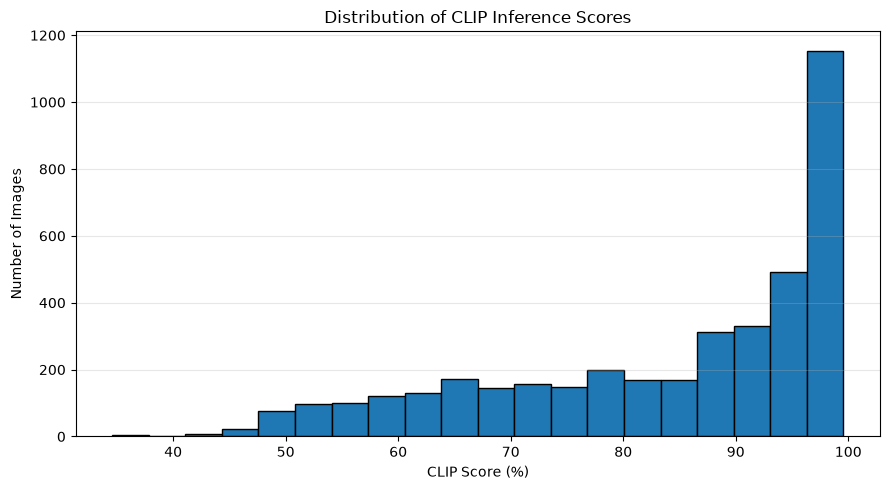

In [9]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(df["score"].dropna(), bins=20, edgecolor="black")
plt.xlabel("CLIP Score (%)")
plt.ylabel("Number of Images")
plt.title("Distribution of CLIP Inference Scores")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 2. ViT-B/16 (`google/vit-base-patch16-224`): pretrained check and full fine-tuning

In [11]:
from transformers import (
    AutoImageProcessor,
    AutoModelForImageClassification
)
import torch

model_id = "google/vit-base-patch16-224"
device = "cuda" if torch.cuda.is_available() else "cpu"

processor = AutoImageProcessor.from_pretrained(model_id)
vit_model = AutoModelForImageClassification.from_pretrained(
    model_id
).to(device)

vit_model.eval()

print("Device:", device)
print("Model loaded:", model_id)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

<venv>\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in <home>/.cache\huggingface\hub\models--google--vit-base-patch16-224. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Device: cuda
Model loaded: google/vit-base-patch16-224


In [14]:

import cv2
import torch
from PIL import Image

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Could not open webcam.")

try:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Convert OpenCV frame (BGR) to PIL image (RGB)
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        pil_image = Image.fromarray(rgb_frame)

        # Preprocess image for ViT
        inputs = processor(
            images=pil_image,
            return_tensors="pt"
        ).to(device)

        # Run inference
        with torch.inference_mode():
            outputs = vit_model(**inputs)

        predicted_id = outputs.logits.argmax(dim=-1).item()
        label = vit_model.config.id2label[predicted_id]

        # Display prediction
        cv2.putText(
            frame,
            label,
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

        cv2.imshow("Pretrained ViT Webcam Inference", frame)

        # Press Q to exit
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()


## Dataset checks and ViT-B/16 fine-tuning setup

Verifies the class folders, then builds a stratified 80/20 split (`random_state=42`) with class-weighted cross-entropy to handle the very small `Background` class.

In [15]:
from pathlib import Path

data_dir = PROJECT_ROOT / "data"

for class_name in ["Plastic", "Non_Plastic", "Background"]:
    folder = data_dir / class_name
    if folder.exists():
        images = [
            p for p in folder.rglob("*")
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
        ]
        print(f"{class_name}: {len(images)} images")
    else:
        print(f"{class_name}: FOLDER NOT FOUND")

Plastic: 2242 images
Non_Plastic: 1737 images
Background: 28 images


In [16]:
import torch
import torchvision
import transformers
import sklearn
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Transformers: 5.20.1
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [17]:
from pathlib import Path
from PIL import Image

DATA_DIR = PROJECT_ROOT / "data"

CLASS_NAMES = ["Background", "Non_Plastic", "Plastic"]

for name in CLASS_NAMES:
    folder = DATA_DIR / name

    if not folder.exists():
        raise FileNotFoundError(f"Folder not found: {folder}")

    images = [
        p for p in folder.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]

    valid_count = 0
    for path in images:
        try:
            with Image.open(path) as img:
                img.verify()
            valid_count += 1
        except Exception:
            print("Unreadable image:", path)

    print(f"{name}: {valid_count} valid images")

Background: 28 valid images
Non_Plastic: 1737 valid images
Plastic: 2242 valid images


In [18]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from transformers import AutoImageProcessor, AutoModelForImageClassification
from sklearn.model_selection import train_test_split
from collections import Counter
import numpy as np

MODEL_ID = "google/vit-base-patch16-224"
OUTPUT_DIR = PROJECT_ROOT / "best_vit_model"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

processor = AutoImageProcessor.from_pretrained(MODEL_ID)

# Match the preprocessing expected by the pretrained model
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=processor.image_mean,
        std=processor.image_std
    )
])

dataset = ImageFolder(DATA_DIR, transform=image_transform)

print("Class mapping:", dataset.class_to_idx)
print("Total images:", len(dataset))

# Stratified split keeps each class represented in both sets
targets = np.array(dataset.targets)
indices = np.arange(len(dataset))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=targets
)

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Using device: cuda
Class mapping: {'Background': 0, 'Non_Plastic': 1, 'Plastic': 2}
Total images: 4007
Training images: 3205
Validation images: 802


In [19]:
# Use a small batch size to fit the model on your GPU
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,  # Reliable default for Windows/Jupyter
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

# Calculate class weights from training data only
train_targets = targets[train_idx]
class_counts = np.bincount(
    train_targets,
    minlength=len(dataset.classes)
)

class_weights = len(train_targets) / (
    len(dataset.classes) * np.maximum(class_counts, 1)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("Class names:", dataset.classes)
print("Training counts:", dict(zip(dataset.classes, class_counts.tolist())))
print("Class weights:", class_weights.cpu().tolist())

Class names: ['Background', 'Non_Plastic', 'Plastic']
Training counts: {'Background': 23, 'Non_Plastic': 1389, 'Plastic': 1793}
Class weights: [46.449275970458984, 0.7691384553909302, 0.5958356857299805]


In [20]:
id2label = {i: name for i, name in enumerate(dataset.classes)}
label2id = {name: i for i, name in id2label.items()}

vit_model = AutoModelForImageClassification.from_pretrained(
    MODEL_ID,
    num_labels=len(dataset.classes),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    vit_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

print("Model ready.")
print("Labels:", vit_model.config.id2label)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([3, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([3])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Model ready.
Labels: {0: 'Background', 1: 'Non_Plastic', 2: 'Plastic'}


In [22]:
from tqdm.auto import tqdm
import pandas as pd
import time

EPOCHS = 20
history = []

scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

for epoch in range(EPOCHS):
    start_time = time.time()

    # ---------- Training ----------
    vit_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS} - Train"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = vit_model(pixel_values=images)
            loss = criterion(outputs.logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (outputs.logits.argmax(1) == labels).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # ---------- Validation ----------
    vit_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in tqdm(
            val_loader, desc=f"Epoch {epoch + 1}/{EPOCHS} - Val"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = vit_model(pixel_values=images)
                loss = criterion(outputs.logits, labels)

            batch_size = labels.size(0)
            val_loss_sum += loss.item() * batch_size
            val_correct += (outputs.logits.argmax(1) == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    record = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy
    }
    history.append(record)

    print(
        f"\nEpoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Train acc: {train_accuracy:.2%} | "
        f"Val acc: {val_accuracy:.2%} | "
        f"Time: {(time.time() - start_time):.1f}s\n"
    )

    # Save the best model based on validation loss
    if val_loss == min(item["val_loss"] for item in history):
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        vit_model.save_pretrained(OUTPUT_DIR)
        processor.save_pretrained(OUTPUT_DIR)

# Save training history for plotting later
history_df = pd.DataFrame(history)
history_df.to_csv(DATA_DIR / "vit_training_history.csv", index=False)

print("Training complete.")
print("History saved to:", DATA_DIR / "vit_training_history.csv")
print("Best model directory:", OUTPUT_DIR)

Epoch 1/20 - Train:   0%|          | 0/401 [00:00<?, ?it/s]

Epoch 1/20 - Val:   0%|          | 0/101 [00:00<?, ?it/s]


Epoch 1/20 | Train loss: 0.0000 | Val loss: 0.0000 | Train acc: 100.00% | Val acc: 100.00% | Time: 41.7s



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 2/20 - Train:   0%|          | 0/401 [00:00<?, ?it/s]

...

Epoch 20/20 - Train:   0%|          | 0/401 [00:00<?, ?it/s]

Epoch 20/20 - Val:   0%|          | 0/101 [00:00<?, ?it/s]


Epoch 20/20 | Train loss: 0.0000 | Val loss: 0.0000 | Train acc: 100.00% | Val acc: 100.00% | Time: 40.4s



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training complete.
History saved to: data\vit_training_history.csv
Best model directory: best_vit_model


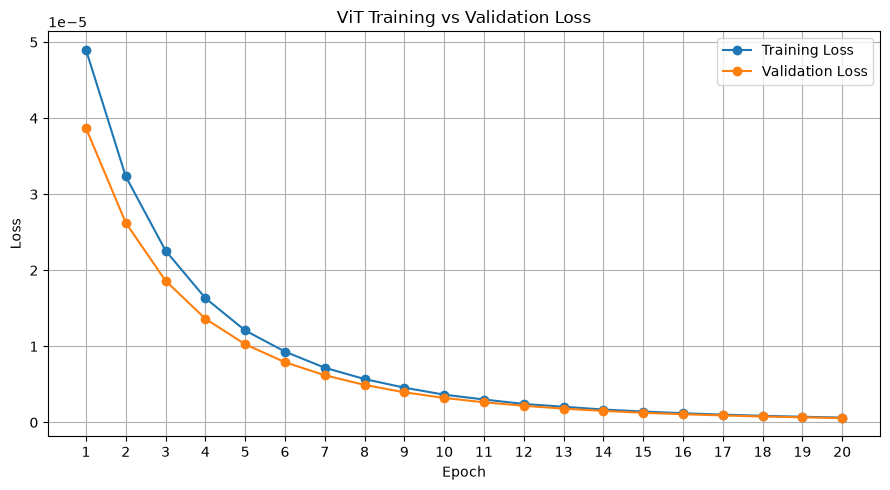

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o",
         label="Training Loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o",
         label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ViT Training vs Validation Loss")
plt.xticks(history_df["epoch"])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

  Background       1.00      1.00      1.00         5
 Non_Plastic       1.00      1.00      1.00       348
     Plastic       1.00      1.00      1.00       449

    accuracy                           1.00       802
   macro avg       1.00      1.00      1.00       802
weighted avg       1.00      1.00      1.00       802



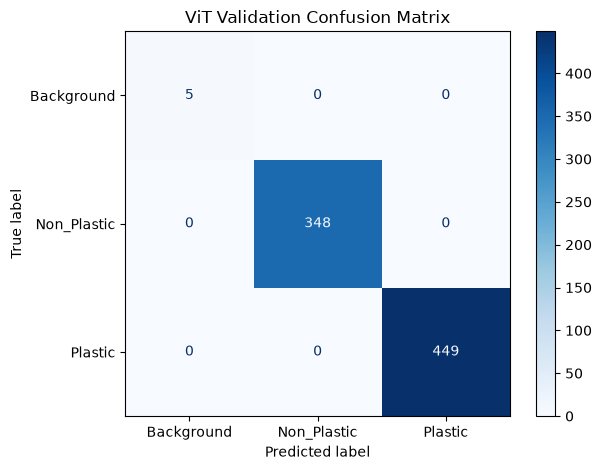

In [24]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

vit_model.eval()
all_predictions = []
all_labels = []

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(device)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            logits = vit_model(pixel_values=images).logits

        all_predictions.extend(logits.argmax(1).cpu().tolist())
        all_labels.extend(labels.tolist())

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(dataset.classes))),
    target_names=dataset.classes,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(dataset.classes)))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.classes
).plot(cmap="Blues", values_format="d")

plt.title("ViT Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [25]:
import cv2
import torch
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForImageClassification

MODEL_DIR = str(PROJECT_ROOT / "best_vit_model")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

webcam_processor = AutoImageProcessor.from_pretrained(MODEL_DIR)
webcam_model = AutoModelForImageClassification.from_pretrained(
    MODEL_DIR
).to(device)

webcam_model.eval()

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Could not open webcam.")

try:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        pil_image = Image.fromarray(rgb)

        inputs = webcam_processor(
            images=pil_image,
            return_tensors="pt"
        ).to(device)

        with torch.inference_mode():
            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                logits = webcam_model(**inputs).logits

            probabilities = torch.softmax(logits.float(), dim=-1)[0]
            predicted_id = probabilities.argmax().item()
            label = webcam_model.config.id2label[predicted_id]
            confidence = probabilities[predicted_id].item()

        text = f"{label}: {confidence:.1%}"
        cv2.putText(
            frame, text, (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8,
            (0, 255, 0), 2
        )

        cv2.imshow("Fine-tuned ViT", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
finally:
    cap.release()
    cv2.destroyAllWindows()

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

## 3. DINOv2 ViT-S/14 (`facebook/dinov2-small`): frozen backbone + linear head, Optuna-tuned

In [35]:
import sys
import torch
import torchvision

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ))
else:
    raise RuntimeError(
        "CUDA is unavailable. Select your GPU-enabled environment as the "
        "VS Code notebook kernel before continuing."
    )

Python executable: <venv>\Scripts\python.exe
Python version: 3.11.3 (tags/v3.11.3:f3909b8, Apr  4 2023, 23:49:59) [MSC v.1934 64 bit (AMD64)]
PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
CUDA build: 12.8
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
GPU memory (GB): 7.93


In [74]:
# Automatic hyperparameter tuning
N_TRIALS = 20
MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 4

BATCH_SIZE_OPTIONS = [8, 16, 32, 64]

LEARNING_RATE_RANGE = (1e-5, 1e-2)
WEIGHT_DECAY_RANGE = (1e-6, 1e-2)

DROPOUT_OPTIONS = [0.0, 0.1, 0.2, 0.3]

In [75]:
from torchvision import datasets, transforms
from transformers import AutoImageProcessor

processor = AutoImageProcessor.from_pretrained(MODEL_ID)

# Fixed dimensions: avoids the previous SizeDict/Resize error.
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=processor.image_mean,
        std=processor.image_std
    )
])

dataset = datasets.ImageFolder(
    root=str(DATA_DIR),
    transform=image_transform
)

class_names = dataset.classes
class_to_idx = dataset.class_to_idx
num_classes = len(class_names)

print("Classes:", class_names)
print("Class mapping:", class_to_idx)
print("Total images:", len(dataset))
print("\nImages per class:")

class_counts = np.bincount(
    dataset.targets, minlength=num_classes
)

for name, count in zip(class_names, class_counts):
    print(f"{name}: {count}")

if num_classes < 2:
    raise ValueError("At least two class folders are required.")

if len(dataset) == 0:
    raise ValueError("No valid images found in the dataset.")

if min(class_counts) < 2:
    raise ValueError(
        "At least two images per class are needed for a stratified split."
    )

print("\nDataset loaded successfully.")

Classes: ['Background', 'Non_Plastic', 'Plastic']
Class mapping: {'Background': 0, 'Non_Plastic': 1, 'Plastic': 2}
Total images: 4007

Images per class:
Background: 28
Non_Plastic: 1737
Plastic: 2242

Dataset loaded successfully.


In [76]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

all_indices = np.arange(len(dataset))
all_targets = np.array(dataset.targets)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=all_targets
)

train_dataset = Subset(dataset, train_indices.tolist())
val_dataset = Subset(dataset, val_indices.tolist())

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("\nTraining class counts:")
train_targets = all_targets[train_indices]
for i, name in enumerate(class_names):
    print(f"{name}: {(train_targets == i).sum()}")

print("\nValidation class counts:")
val_targets = all_targets[val_indices]
for i, name in enumerate(class_names):
    print(f"{name}: {(val_targets == i).sum()}")

Training images: 3205
Validation images: 802

Training class counts:
Background: 23
Non_Plastic: 1389
Plastic: 1793

Validation class counts:
Background: 5
Non_Plastic: 348
Plastic: 449


In [77]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label sample:", labels[:10].tolist())

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
print("DataLoader test passed.")

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image dtype: torch.float32
Label sample: [1, 2, 0, 2, 2, 2, 2, 1, 1, 1]
DataLoader test passed.


In [78]:
class DINOv2Classifier(nn.Module):
    def __init__(self, model_id, num_classes, dropout=0.1):
        super().__init__()

        self.backbone = AutoModel.from_pretrained(model_id)

        for parameter in self.backbone.parameters():
            parameter.requires_grad = False

        hidden_size = self.backbone.config.hidden_size

        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(hidden_size, num_classes)
        )

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()
        return self

    def forward(self, pixel_values):
        with torch.no_grad():
            outputs = self.backbone(pixel_values=pixel_values)
            features = outputs.last_hidden_state[:, 0, :]

        return self.classifier(features)

In [79]:
model.eval()

test_images, test_labels = next(iter(train_loader))
test_images = test_images.to(device)

with torch.no_grad():
    with torch.autocast(
        device_type=device.type,
        dtype=torch.float16,
        enabled=USE_AMP
    ):
        test_logits = model(test_images)

print("Input shape:", test_images.shape)
print("Output shape:", test_logits.shape)
print("Expected output shape:", (test_images.shape[0], num_classes))

assert test_logits.shape == (test_images.shape[0], num_classes)
assert torch.isfinite(test_logits).all()

print("Forward-pass test passed.")

Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16, 3])
Expected output shape: (16, 3)
Forward-pass test passed.


In [80]:
import pandas as pd
import optuna
from tqdm.auto import tqdm
from torch.utils.data import DataLoader

# Keep Optuna's output manageable.
optuna.logging.set_verbosity(optuna.logging.WARNING)

best_val_loss_global = float("inf")
trial_results_path = MODEL_DIR / "optuna_trials.csv"

def objective(trial):
    global best_val_loss_global

    # Optuna automatically chooses hyperparameters.
    batch_size = trial.suggest_categorical(
        "batch_size", BATCH_SIZE_OPTIONS
    )
    learning_rate = trial.suggest_float(
        "learning_rate", *LEARNING_RATE_RANGE, log=True
    )
    weight_decay = trial.suggest_float(
        "weight_decay", *WEIGHT_DECAY_RANGE, log=True
    )
    dropout = trial.suggest_categorical(
        "dropout", DROPOUT_OPTIONS
    )

    # Create loaders for this trial's batch size.
    trial_train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    trial_val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    # A fresh model for each trial.
    trial_model = DINOv2Classifier(
        MODEL_ID,
        num_classes,
        dropout=dropout
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.AdamW(
        trial_model.classifier.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    scaler = torch.amp.GradScaler(
        "cuda", enabled=USE_AMP
    )

    best_trial_loss = float("inf")
    epochs_without_improvement = 0

    for epoch in range(MAX_EPOCHS):

        # ---------- Training ----------
        trial_model.train()
        trial_model.backbone.eval()

        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for batch_images, batch_labels in trial_train_loader:
            batch_images = batch_images.to(
                device, non_blocking=True
            )
            batch_labels = batch_labels.to(
                device, non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                logits = trial_model(batch_images)
                loss = criterion(logits, batch_labels)

            if not torch.isfinite(loss):
                raise RuntimeError(
                    "Non-finite loss encountered during tuning."
                )

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            batch_n = batch_labels.size(0)
            train_loss_sum += loss.item() * batch_n
            train_correct += (
                logits.argmax(dim=1) == batch_labels
            ).sum().item()
            train_total += batch_n

        train_loss = train_loss_sum / train_total
        train_accuracy = train_correct / train_total

        # ---------- Validation ----------
        trial_model.eval()

        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for batch_images, batch_labels in trial_val_loader:
                batch_images = batch_images.to(
                    device, non_blocking=True
                )
                batch_labels = batch_labels.to(
                    device, non_blocking=True
                )

                with torch.autocast(
                    device_type=device.type,
                    dtype=torch.float16,
                    enabled=USE_AMP
                ):
                    logits = trial_model(batch_images)
                    loss = criterion(logits, batch_labels)

                batch_n = batch_labels.size(0)
                val_loss_sum += loss.item() * batch_n
                val_correct += (
                    logits.argmax(dim=1) == batch_labels
                ).sum().item()
                val_total += batch_n

        val_loss = val_loss_sum / val_total
        val_accuracy = val_correct / val_total

        # Record each epoch for this trial.
        trial.report(val_loss, step=epoch)

        print(
            f"Trial {trial.number + 1}/{N_TRIALS} | "
            f"Epoch {epoch + 1}/{MAX_EPOCHS} | "
            f"Batch={batch_size} | LR={learning_rate:.2e} | "
            f"WD={weight_decay:.2e} | Dropout={dropout} | "
            f"Train acc={train_accuracy:.2%} | "
            f"Val acc={val_accuracy:.2%} | "
            f"Val loss={val_loss:.4f}"
        )

        # Save the globally best model checkpoint.
        if val_loss < best_val_loss_global:
            best_val_loss_global = val_loss

            torch.save({
                "model_state_dict": trial_model.state_dict(),
                "class_names": class_names,
                "class_to_idx": class_to_idx,
                "model_id": MODEL_ID,
                "image_size": IMAGE_SIZE,
                "mean": processor.image_mean,
                "std": processor.image_std,
                "dropout": dropout,
                "batch_size": batch_size,
                "learning_rate": learning_rate,
                "weight_decay": weight_decay,
                "epoch": epoch + 1,
                "trial_number": trial.number,
                "val_loss": val_loss,
                "val_accuracy": val_accuracy
            }, CHECKPOINT_PATH)

            print(f"  New best model saved: {CHECKPOINT_PATH}")

        # Early stopping within this trial.
        if val_loss < best_trial_loss:
            best_trial_loss = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print("  Early stopping: validation loss did not improve.")
            break

        # Allow Optuna to prune underperforming trials.
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("best_val_loss", best_trial_loss)
    return best_trial_loss


# MedianPruner may stop weak trials early.
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=3,
        n_warmup_steps=2
    )
)

study.optimize(
    objective,
    n_trials=N_TRIALS,
    gc_after_trial=True
)

# Save every trial's hyperparameters and results.
trials_df = study.trials_dataframe()
trials_df.to_csv(trial_results_path, index=False)

print("\n========== TUNING COMPLETE ==========")
print("Best validation loss:", study.best_value)
print("Best hyperparameters:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

print("\nBest model checkpoint:", CHECKPOINT_PATH)
print("All trial results:", trial_results_path)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Trial 1/20 | Epoch 1/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | Dropout=0.1 | Train acc=59.56% | Val acc=79.93% | Val loss=0.5898
  New best model saved: dinov2_model\best_model.pth
Trial 1/20 | Epoch 2/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | Dropout=0.1 | Train acc=82.75% | Val acc=90.27% | Val loss=0.3477
  New best model saved: dinov2_model\best_model.pth
Trial 1/20 | Epoch 3/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | Dropout=0.1 | Train acc=90.27% | Val acc=94.14% | Val loss=0.2321
  New best model saved: dinov2_model\best_model.pth
Trial 1/20 | Epoch 4/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | Dropout=0.1 | Train acc=93.67% | Val acc=97.01% | Val loss=0.1674
  New best model saved: dinov2_model\best_model.pth
Trial 1/20 | Epoch 5/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | Dropout=0.1 | Train acc=96.01% | Val acc=98.38% | Val loss=0.1261
  New best model saved: dinov2_model\best_model.pth
Trial 1/20 | Epoch 6/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | Dropout=0.1 | Train 

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Trial 2/20 | Epoch 1/50 | Batch=16 | LR=3.51e-05 | WD=5.42e-06 | Dropout=0.1 | Train acc=49.02% | Val acc=70.95% | Val loss=0.6819
Trial 2/20 | Epoch 2/50 | Batch=16 | LR=3.51e-05 | WD=5.42e-06 | Dropout=0.1 | Train acc=78.72% | Val acc=87.91% | Val loss=0.3869
Trial 2/20 | Epoch 3/50 | Batch=16 | LR=3.51e-05 | WD=5.42e-06 | Dropout=0.1 | Train acc=89.39% | Val acc=94.64% | Val loss=0.2590
Trial 2/20 | Epoch 4/50 | Batch=16 | LR=3.51e-05 | WD=5.42e-06 | Dropout=0.1 | Train acc=94.41% | Val acc=96.01% | Val loss=0.1874
Trial 2/20 | Epoch 5/50 | Batch=16 | LR=3.51e-05 | WD=5.42e-06 | Dropout=0.1 | Train acc=96.07% | Val acc=96.76% | Val loss=0.1405
Trial 2/20 | Epoch 6/50 | Batch=16 | LR=3.51e-05 | WD=5.42e-06 | Dropout=0.1 | Train acc=97.22% | Val acc=97.01% | Val loss=0.1089
Trial 2/20 | Epoch 7/50 | Batch=16 | LR=3.51e-05 | WD=5.42e-06 | Dropout=0.1 | Train acc=97.69% | Val acc=97.63% | Val loss=0.0850
Trial 2/20 | Epoch 8/50 | Batch=16 | LR=3.51e-05 | WD=5.42e-06 | Dropout=0.1 | Trai

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

...

Trial 18/20 | Epoch 1/50 | Batch=32 | LR=7.13e-03 | WD=2.74e-06 | Dropout=0.2 | Train acc=97.60% | Val acc=100.00% | Val loss=0.0000
Trial 18/20 | Epoch 2/50 | Batch=32 | LR=7.13e-03 | WD=2.74e-06 | Dropout=0.2 | Train acc=100.00% | Val acc=100.00% | Val loss=0.0000
Trial 18/20 | Epoch 3/50 | Batch=32 | LR=7.13e-03 | WD=2.74e-06 | Dropout=0.2 | Train acc=100.00% | Val acc=100.00% | Val loss=0.0000
Trial 18/20 | Epoch 4/50 | Batch=32 | LR=7.13e-03 | WD=2.74e-06 | Dropout=0.2 | Train acc=100.00% | Val acc=100.00% | Val loss=0.0000
Trial 18/20 | Epoch 5/50 | Batch=32 | LR=7.13e-03 | WD=2.74e-06 | Dropout=0.2 | Train acc=100.00% | Val acc=100.00% | Val loss=0.0000
Trial 18/20 | Epoch 6/50 | Batch=32 | LR=7.13e-03 | WD=2.74e-06 | Dropout=0.2 | Train acc=100.00% | Val acc=100.00% | Val loss=0.0000
Trial 18/20 | Epoch 7/50 | Batch=32 | LR=7.13e-03 | WD=2.74e-06 | Dropout=0.2 | Train acc=100.00% | Val acc=100.00% | Val loss=0.0000
Trial 18/20 | Epoch 8/50 | Batch=32 | LR=7.13e-03 | WD=2.74e-06

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Trial 19/20 | Epoch 1/50 | Batch=32 | LR=4.53e-03 | WD=1.85e-05 | Dropout=0.3 | Train acc=95.63% | Val acc=100.00% | Val loss=0.0005
Trial 19/20 | Epoch 2/50 | Batch=32 | LR=4.53e-03 | WD=1.85e-05 | Dropout=0.3 | Train acc=100.00% | Val acc=100.00% | Val loss=0.0002
Trial 19/20 | Epoch 3/50 | Batch=32 | LR=4.53e-03 | WD=1.85e-05 | Dropout=0.3 | Train acc=100.00% | Val acc=100.00% | Val loss=0.0001
Trial 19/20 | Epoch 4/50 | Batch=32 | LR=4.53e-03 | WD=1.85e-05 | Dropout=0.3 | Train acc=99.94% | Val acc=100.00% | Val loss=0.0001
Trial 19/20 | Epoch 5/50 | Batch=32 | LR=4.53e-03 | WD=1.85e-05 | Dropout=0.3 | Train acc=99.88% | Val acc=100.00% | Val loss=0.0001
Trial 19/20 | Epoch 6/50 | Batch=32 | LR=4.53e-03 | WD=1.85e-05 | Dropout=0.3 | Train acc=100.00% | Val acc=100.00% | Val loss=0.0000
Trial 19/20 | Epoch 7/50 | Batch=32 | LR=4.53e-03 | WD=1.85e-05 | Dropout=0.3 | Train acc=100.00% | Val acc=100.00% | Val loss=0.0000
Trial 19/20 | Epoch 8/50 | Batch=32 | LR=4.53e-03 | WD=1.85e-05 |

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Trial 20/20 | Epoch 1/50 | Batch=64 | LR=3.41e-04 | WD=8.51e-06 | Dropout=0.3 | Train acc=61.97% | Val acc=91.15% | Val loss=0.2466
Trial 20/20 | Epoch 2/50 | Batch=64 | LR=3.41e-04 | WD=8.51e-06 | Dropout=0.3 | Train acc=90.55% | Val acc=97.88% | Val loss=0.0986
Trial 20/20 | Epoch 3/50 | Batch=64 | LR=3.41e-04 | WD=8.51e-06 | Dropout=0.3 | Train acc=96.38% | Val acc=99.00% | Val loss=0.0548

========== TUNING COMPLETE ==========
Best validation loss: 0.0
Best hyperparameters:
  batch_size: 8
  learning_rate: 0.001257838923598365
  weight_decay: 1.2877902240342793e-06
  dropout: 0.3

Best model checkpoint: dinov2_model\best_model.pth
All trial results: dinov2_model\optuna_trials.csv


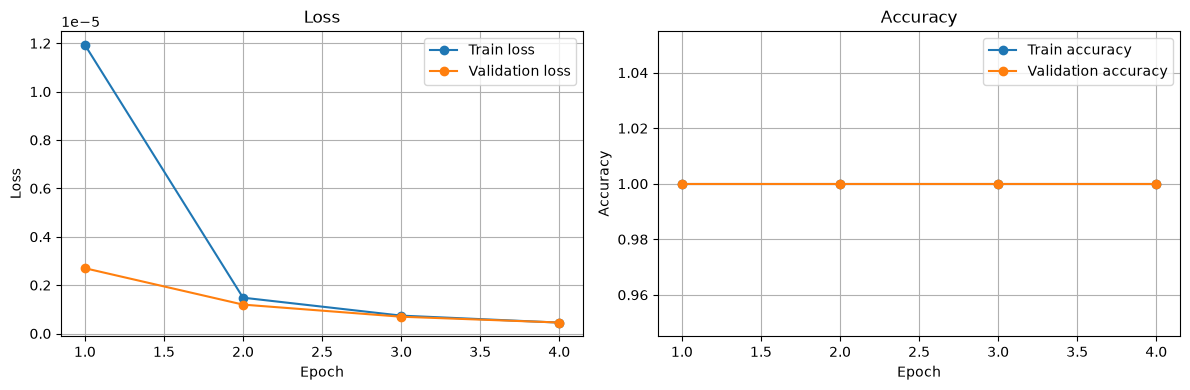

In [81]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"], history_df["train_loss"],
    marker="o", label="Train loss"
)
axes[0].plot(
    history_df["epoch"], history_df["val_loss"],
    marker="o", label="Validation loss"
)
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_df["epoch"], history_df["train_accuracy"],
    marker="o", label="Train accuracy"
)
axes[1].plot(
    history_df["epoch"], history_df["val_accuracy"],
    marker="o", label="Validation accuracy"
)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Best checkpoint epoch: 35
Validation accuracy: 100.00%

Classification report:
              precision    recall  f1-score   support

  Background       1.00      1.00      1.00         5
 Non_Plastic       1.00      1.00      1.00       348
     Plastic       1.00      1.00      1.00       449

    accuracy                           1.00       802
   macro avg       1.00      1.00      1.00       802
weighted avg       1.00      1.00      1.00       802



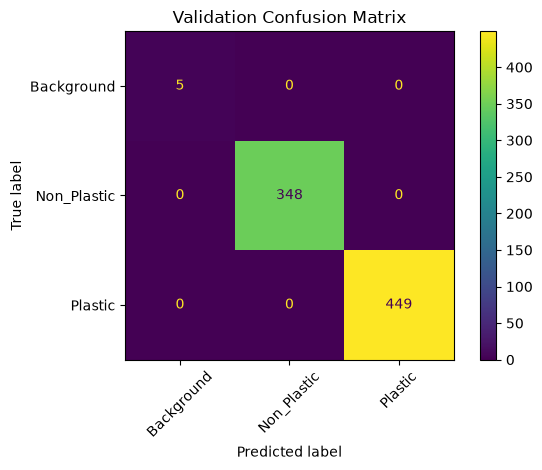

In [82]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

# Rebuild using the same architecture and weights.
best_model = DINOv2Classifier(
    model_id=checkpoint["model_id"],
    num_classes=len(checkpoint["class_names"])
).to(device)

best_model.load_state_dict(checkpoint["model_state_dict"])
best_model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for batch_images, batch_labels in val_loader:
        batch_images = batch_images.to(device)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            logits = best_model(batch_images)

        predictions = logits.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions.tolist())
        y_true.extend(batch_labels.numpy().tolist())

print("Best checkpoint epoch:", checkpoint["epoch"])
print(f"Validation accuracy: {np.mean(np.array(y_true) == np.array(y_pred)):.2%}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred,
    labels=list(range(len(class_names)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display.plot(xticks_rotation=45, values_format="d")
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [83]:
import cv2

camera = cv2.VideoCapture(0, cv2.CAP_DSHOW)

if not camera.isOpened():
    camera.release()
    camera = cv2.VideoCapture(0)

if not camera.isOpened():
    raise RuntimeError(
        "Could not open the webcam. Check camera permissions or try camera index 1."
    )

best_model.eval()

try:
    while True:
        success, frame = camera.read()

        if not success:
            print("Could not read a webcam frame.")
            break

        # OpenCV uses BGR; PIL expects RGB.
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        pil_image = Image.fromarray(rgb_frame)

        input_tensor = image_transform(pil_image).unsqueeze(0).to(device)

        with torch.no_grad():
            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                logits = best_model(input_tensor)

            probabilities = torch.softmax(logits.float(), dim=1)[0]
            predicted_idx = probabilities.argmax().item()
            predicted_class = class_names[predicted_idx]
            score = probabilities[predicted_idx].item()

        label = f"{predicted_class}: {score:.1%}"

        cv2.putText(
            frame,
            label,
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            2,
            cv2.LINE_AA
        )

        cv2.imshow("DINOv2 Plastic Classifier - Press Q to quit", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    camera.release()
    cv2.destroyAllWindows()

## 4. DINOv2 ViT-B/14 (`facebook/dinov2-base`): cached features + linear head, Optuna-tuned

In [91]:
import sys
import torch
import torchvision

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("Select your GPU-enabled VS Code notebook kernel.")

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GB):", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
))

Python: <venv>\Scripts\python.exe
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA: 12.8
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
GPU memory (GB): 7.93


In [92]:
from pathlib import Path
import random
import numpy as np
import torch

PROJECT_DIR = PROJECT_ROOT
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "dinov2_base_model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ID = "facebook/dinov2-base"
IMAGE_SIZE = 224

# Automatic tuning settings
N_TRIALS = 20
MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 4

BATCH_SIZE_OPTIONS = [8, 16, 32, 64]
DROPOUT_OPTIONS = [0.0, 0.1, 0.2, 0.3]
LEARNING_RATE_RANGE = (1e-5, 1e-2)
WEIGHT_DECAY_RANGE = (1e-6, 1e-2)

SEED = 42
VALIDATION_SIZE = 0.20

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda")
USE_AMP = True

CHECKPOINT_PATH = MODEL_DIR / "best_model.pth"
TRIALS_PATH = MODEL_DIR / "optuna_trials.csv"
HISTORY_PATH = MODEL_DIR / "best_trial_history.csv"

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATA_DIR}")

print("Model:", MODEL_ID)
print("Device:", torch.cuda.get_device_name(0))
print("Dataset:", DATA_DIR)
print("Output:", MODEL_DIR)

Model: facebook/dinov2-base
Device: NVIDIA GeForce RTX 5060 Laptop GPU
Dataset: data
Output: dinov2_base_model


In [93]:
from torchvision import datasets, transforms
from transformers import AutoImageProcessor

processor = AutoImageProcessor.from_pretrained(MODEL_ID)

image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=processor.image_mean,
        std=processor.image_std
    )
])

dataset = datasets.ImageFolder(
    root=str(DATA_DIR),
    transform=image_transform
)

class_names = dataset.classes
class_to_idx = dataset.class_to_idx
num_classes = len(class_names)
targets = np.array(dataset.targets)

print("Classes:", class_names)
print("Class mapping:", class_to_idx)
print("Total images:", len(dataset))

for i, name in enumerate(class_names):
    print(f"{name}: {(targets == i).sum()} images")

if num_classes < 2:
    raise ValueError("At least two class folders are required.")

if min(np.bincount(targets, minlength=num_classes)) < 2:
    raise ValueError("Each class needs at least two valid images.")

Classes: ['Background', 'Non_Plastic', 'Plastic']
Class mapping: {'Background': 0, 'Non_Plastic': 1, 'Plastic': 2}
Total images: 4007
Background: 28 images
Non_Plastic: 1737 images
Plastic: 2242 images


In [94]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

indices = np.arange(len(dataset))

train_indices, val_indices = train_test_split(
    indices,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=targets
)

train_dataset = Subset(dataset, train_indices.tolist())
val_dataset = Subset(dataset, val_indices.tolist())

train_targets = targets[train_indices]
val_targets = targets[val_indices]

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 3205
Validation images: 802


In [95]:
from transformers import AutoModel
from torch.utils.data import DataLoader

backbone = AutoModel.from_pretrained(MODEL_ID).to(device)
backbone.eval()

for parameter in backbone.parameters():
    parameter.requires_grad = False

FEATURE_BATCH_SIZE = 8  # Conservative starting point for ViT-B/14

def extract_features(subset, description):
    loader = DataLoader(
        subset,
        batch_size=FEATURE_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    all_features = []
    all_labels = []

    with torch.inference_mode():
        for images, labels in tqdm(loader, desc=description):
            images = images.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                outputs = backbone(pixel_values=images)
                features = outputs.last_hidden_state[:, 0, :]

            all_features.append(features.float().cpu())
            all_labels.append(labels.cpu())

    return torch.cat(all_features), torch.cat(all_labels)

from tqdm.auto import tqdm

train_features, train_labels = extract_features(
    train_dataset, "Extracting training features"
)

val_features, val_labels = extract_features(
    val_dataset, "Extracting validation features"
)

print("Training features:", tuple(train_features.shape))
print("Validation features:", tuple(val_features.shape))
print("Feature extraction complete.")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Extracting training features:   0%|          | 0/401 [00:00<?, ?it/s]

Extracting validation features:   0%|          | 0/101 [00:00<?, ?it/s]

Training features: (3205, 768)
Validation features: (802, 768)
Feature extraction complete.


In [96]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

hidden_size = int(backbone.config.hidden_size)

class ClassifierHead(nn.Module):
    def __init__(self, hidden_size, num_classes, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, features):
        return self.layers(features)

counts = np.bincount(
    train_labels.numpy(), minlength=num_classes
)

weights = len(train_labels) / (
    num_classes * np.maximum(counts, 1)
)

class_weights = torch.tensor(
    weights, dtype=torch.float32, device=device
)

print("Feature size:", hidden_size)
print("Class weights:", class_weights.cpu().tolist())

Feature size: 768
Class weights: [46.449275970458984, 0.7691384553909302, 0.5958356857299805]


In [97]:
import optuna
import pandas as pd
import gc

optuna.logging.set_verbosity(optuna.logging.WARNING)

best_val_loss_global = float("inf")
best_trial_history = []

train_feature_dataset = TensorDataset(train_features, train_labels)
val_feature_dataset = TensorDataset(val_features, val_labels)

def objective(trial):
    global best_val_loss_global, best_trial_history

    batch_size = trial.suggest_categorical(
        "batch_size", BATCH_SIZE_OPTIONS
    )
    learning_rate = trial.suggest_float(
        "learning_rate", *LEARNING_RATE_RANGE, log=True
    )
    weight_decay = trial.suggest_float(
        "weight_decay", *WEIGHT_DECAY_RANGE, log=True
    )
    dropout = trial.suggest_categorical(
        "dropout", DROPOUT_OPTIONS
    )

    train_loader = DataLoader(
        train_feature_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )
    val_loader = DataLoader(
        val_feature_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    head = ClassifierHead(
        hidden_size, num_classes, dropout
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.AdamW(
        head.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    best_trial_loss = float("inf")
    epochs_without_improvement = 0
    trial_history = []
    best_head_state = None
    best_epoch = 0

    for epoch in range(MAX_EPOCHS):
        # ---- Training ----
        head.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for features, labels in train_loader:
            features = features.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                logits = head(features)
                loss = criterion(logits, labels)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss.")

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            n = labels.size(0)
            train_loss_sum += loss.item() * n
            train_correct += (logits.argmax(1) == labels).sum().item()
            train_total += n

        train_loss = train_loss_sum / train_total
        train_accuracy = train_correct / train_total

        # ---- Validation ----
        head.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for features, labels in val_loader:
                features = features.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16,
                    enabled=USE_AMP
                ):
                    logits = head(features)
                    loss = criterion(logits, labels)

                n = labels.size(0)
                val_loss_sum += loss.item() * n
                val_correct += (logits.argmax(1) == labels).sum().item()
                val_total += n

        val_loss = val_loss_sum / val_total
        val_accuracy = val_correct / val_total

        trial_history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        })

        print(
            f"Trial {trial.number + 1}/{N_TRIALS} | "
            f"Epoch {epoch + 1}/{MAX_EPOCHS} | "
            f"Batch={batch_size} | LR={learning_rate:.2e} | "
            f"WD={weight_decay:.2e} | Dropout={dropout} | "
            f"Train acc={train_accuracy:.2%} | "
            f"Val acc={val_accuracy:.2%} | "
            f"Val loss={val_loss:.4f}"
        )

        # Keep the best epoch for this trial.
        if val_loss < best_trial_loss:
            best_trial_loss = val_loss
            best_epoch = epoch + 1
            best_head_state = {
                key: value.detach().cpu().clone()
                for key, value in head.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        trial.report(val_loss, step=epoch)

        # Save global best classifier head and settings.
        if val_loss < best_val_loss_global:
            best_val_loss_global = val_loss
            best_trial_history = trial_history.copy()

            torch.save({
                "classifier_state_dict": best_head_state,
                "class_names": class_names,
                "class_to_idx": class_to_idx,
                "model_id": MODEL_ID,
                "image_size": IMAGE_SIZE,
                "mean": processor.image_mean,
                "std": processor.image_std,
                "hidden_size": hidden_size,
                "dropout": dropout,
                "batch_size": batch_size,
                "learning_rate": learning_rate,
                "weight_decay": weight_decay,
                "trial_number": trial.number,
                "epoch": best_epoch,
                "val_loss": best_trial_loss
            }, CHECKPOINT_PATH)

            print("  New best head saved:", CHECKPOINT_PATH)

        if trial.should_prune():
            raise optuna.TrialPruned()

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print("  Early stopping this trial.")
            break

    trial.set_user_attr("best_epoch", best_epoch)
    trial.set_user_attr("best_val_loss", best_trial_loss)
    trial.set_user_attr("best_val_accuracy", max(
        row["val_accuracy"] for row in trial_history
    ))

    # Save the best epoch history for this trial if it became the global best.
    del head, optimizer, scaler
    gc.collect()
    torch.cuda.empty_cache()

    return best_trial_loss


study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=3,
        n_warmup_steps=3
    )
)

study.optimize(
    objective,
    n_trials=N_TRIALS,
    gc_after_trial=True
)

study.trials_dataframe().to_csv(TRIALS_PATH, index=False)
pd.DataFrame(best_trial_history).to_csv(HISTORY_PATH, index=False)

print("\n===== OPTUNA COMPLETE =====")
print("Best validation loss:", study.best_value)
print("Best hyperparameters:", study.best_params)
print("Best checkpoint:", CHECKPOINT_PATH)
print("All trials:", TRIALS_PATH)

Trial 1/20 | Epoch 1/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | Dropout=0.1 | Train acc=63.06% | Val acc=89.90% | Val loss=0.5162
  New best head saved: dinov2_base_model\best_model.pth
Trial 1/20 | Epoch 2/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | Dropout=0.1 | Train acc=92.67% | Val acc=97.51% | Val loss=0.2774
  New best head saved: dinov2_base_model\best_model.pth
Trial 1/20 | Epoch 3/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | Dropout=0.1 | Train acc=96.94% | Val acc=98.63% | Val loss=0.1754
  New best head saved: dinov2_base_model\best_model.pth
Trial 1/20 | Epoch 4/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | Dropout=0.1 | Train acc=97.91% | Val acc=98.88% | Val loss=0.1218
  New best head saved: dinov2_base_model\best_model.pth
Trial 1/20 | Epoch 5/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | Dropout=0.1 | Train acc=98.47% | Val acc=99.13% | Val loss=0.0896
  New best head saved: dinov2_base_model\best_model.pth
Trial 1/20 | Epoch 6/50 | Batch=16 | LR=2.94e-05 | WD=4.21e-06 | 

In [99]:
# Cell 8: Display Hyperparameter Tuning Results

import pandas as pd
from IPython.display import display as show_table

# Check whether Optuna study exists
if "study" not in globals():
    print("Error: Optuna study not found. Run Cell 7 first.")

elif len(study.trials) == 0:
    print("No trials found. Run Cell 7 to start hyperparameter tuning.")

else:
    # Collect trial results
    results = study.trials_dataframe()

    # Select useful columns that actually exist
    display_columns = [
        "number",
        "value",
        "params_batch_size",
        "params_learning_rate",
        "params_weight_decay",
        "params_dropout",
        "state"
    ]

    available_columns = [
        col for col in display_columns
        if col in results.columns
    ]

    # Display trials sorted by validation loss
    if "value" in results.columns:
        results = results.sort_values("value", ascending=True)

    print(f"Total trials: {len(study.trials)}")
    print(f"Completed trials: {sum(t.state.name == 'COMPLETE' for t in study.trials)}")
    print("\nHyperparameter tuning results:")

    show_table(
        results[available_columns].reset_index(drop=True)
    )

    # Display best trial
    if study.best_trial is not None:
        print("\nBest Trial:")
        print(f"Best validation loss: {study.best_value:.4f}")
        print("Best hyperparameters:")

        for parameter, value in study.best_params.items():
            print(f"  {parameter}: {value}")

Total trials: 20
Completed trials: 10

Hyperparameter tuning results:


,number,value,params_batch_size,params_learning_rate,params_weight_decay,params_dropout,state
0,15,0.000000e+00,8,0.005787,0.000009,0.2,COMPLETE
1,16,0.000000e+00,8,0.004830,0.000011,0.2,COMPLETE
2,17,1.675120e-10,8,0.006345,0.000008,0.2,COMPLETE
3,11,3.350239e-10,8,0.001009,0.000020,0.3,COMPLETE
4,5,6.033564e-10,8,0.000622,0.004870,0.3,COMPLETE
5,10,1.115729e-08,8,0.001258,0.000001,0.3,COMPLETE
6,2,5.631666e-08,8,0.000233,0.001383,0.2,COMPLETE
7,18,6.561987e-07,16,0.005371,0.000065,0.2,PRUNED
8,3,7.315403e-07,64,0.007887,0.001712,0.2,COMPLETE
9,9,5.418463e-05,32,0.002055,0.000094,0.0,PRUNED



Best Trial:
Best validation loss: 0.0000
Best hyperparameters:
  batch_size: 8
  learning_rate: 0.005787292045807483
  weight_decay: 8.753957977882123e-06
  dropout: 0.2


In [101]:
import matplotlib.pyplot as plt
from pathlib import Path

# Check available training history
print("history exists:", "history" in globals())
print("MODEL_DIR:", MODEL_DIR)

# Try to locate saved history
history_files = list(Path(MODEL_DIR).glob("*history*"))
print("History files:", history_files)

history exists: True
MODEL_DIR: dinov2_base_model
History files: [WindowsPath('dinov2_base_model/best_trial_history.csv')]


Available keys: dict_keys(['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy'])


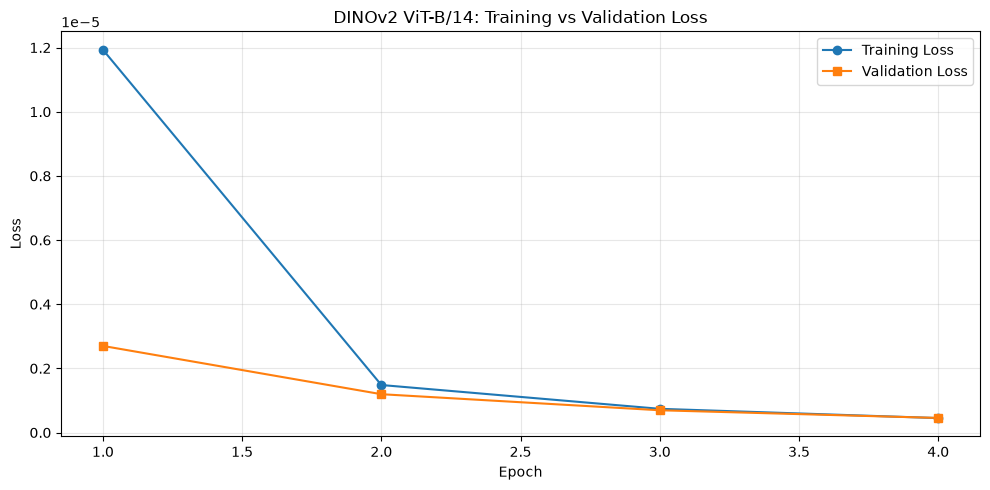

In [103]:
import matplotlib.pyplot as plt

if isinstance(history, list) and history and isinstance(history[0], dict):
    print("Available keys:", history[0].keys())

    train_losses = [item["train_loss"] for item in history]
    val_losses = [item["val_loss"] for item in history]

    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(train_losses) + 1), train_losses,
             marker="o", label="Training Loss")
    plt.plot(range(1, len(val_losses) + 1), val_losses,
             marker="s", label="Validation Loss")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("DINOv2 ViT-B/14: Training vs Validation Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("History format differs from the expected format.")
    print("Run Step 1 and share its output.")

Validation accuracy: 100.00%

Classification report:
              precision    recall  f1-score   support

  Background       1.00      1.00      1.00         5
 Non_Plastic       1.00      1.00      1.00       348
     Plastic       1.00      1.00      1.00       449

    accuracy                           1.00       802
   macro avg       1.00      1.00      1.00       802
weighted avg       1.00      1.00      1.00       802



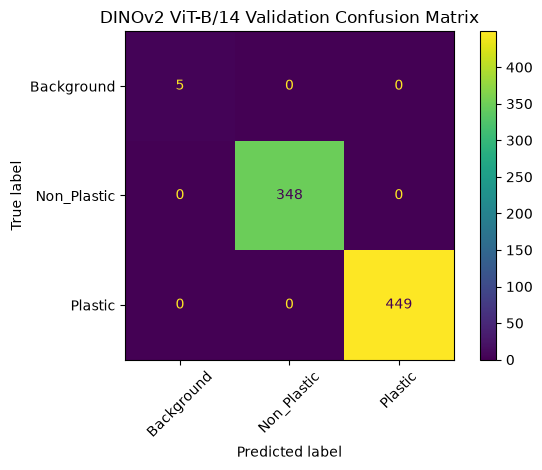

In [104]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

best_head = ClassifierHead(
    checkpoint["hidden_size"],
    len(checkpoint["class_names"]),
    checkpoint["dropout"]
).to(device)

best_head.load_state_dict(checkpoint["classifier_state_dict"])
best_head.eval()

predictions = []

with torch.no_grad():
    for start in range(0, len(val_features), 128):
        batch = val_features[start:start + 128].to(device)
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            logits = best_head(batch)
        predictions.extend(logits.argmax(1).cpu().tolist())

y_true = val_labels.numpy()
y_pred = np.array(predictions)

print("Validation accuracy:", f"{(y_true == y_pred).mean():.2%}")
print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(xticks_rotation=45, values_format="d")

plt.title("DINOv2 ViT-B/14 Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [111]:

# DINOv2 ViT-B/14 — Complete Webcam Inference

import cv2
import torch
import torch.nn as nn
from pathlib import Path
from PIL import Image
from transformers import AutoImageProcessor, AutoModel

# 1. Configuration
PROJECT_DIR = PROJECT_ROOT
MODEL_DIR = PROJECT_DIR / "dinov2_base_model"
MODEL_ID = "facebook/dinov2-base"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Get class names from the original dataset
# train_dataset is a Subset, so access its underlying ImageFolder
if hasattr(train_dataset, "classes"):
    class_names = train_dataset.classes
else:
    class_names = train_dataset.dataset.classes

print("Classes:", class_names)
print("Device:", device)

# 3. Find saved classifier checkpoint
candidates = [
    MODEL_DIR / "best_head.pt",
    MODEL_DIR / "best_model.pt",
    MODEL_DIR / "best_head.pth",
    MODEL_DIR / "best_model.pth",
]

checkpoint_path = next((p for p in candidates if p.exists()), None)

if checkpoint_path is None:
    print("Checkpoint files:", [
        p.name for p in MODEL_DIR.glob("*.pt")
    ] + [
        p.name for p in MODEL_DIR.glob("*.pth")
    ])
    raise FileNotFoundError(
        "Update checkpoint_path to your actual saved classifier file."
    )

print("Checkpoint:", checkpoint_path)

# 4. Load backbone
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
backbone = AutoModel.from_pretrained(MODEL_ID).to(device)
backbone.eval()

hidden_size = backbone.config.hidden_size
num_classes = len(class_names)

# 5. Load the saved classifier
checkpoint = torch.load(
    checkpoint_path, map_location=device, weights_only=True
)

if isinstance(checkpoint, dict):
    state_dict = checkpoint.get(
        "model_state_dict",
        checkpoint.get("state_dict",
        checkpoint.get("classifier_state_dict", checkpoint))
    )
else:
    state_dict = checkpoint

# Match checkpoint parameter names: layers.1.weight / layers.1.bias
class DINOv2Classifier(nn.Module):
    def __init__(self, hidden_size, num_classes):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Dropout(0.0),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, x):
        return self.layers(x)

classifier = DINOv2Classifier(
    hidden_size, num_classes
).to(device)

classifier.load_state_dict(state_dict)
classifier.eval()

print("Classifier loaded successfully!")

# 6. Start webcam
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Cannot open webcam. Try camera index 1.")

try:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image = Image.fromarray(rgb)
        inputs = processor(images=image, return_tensors="pt")
        pixel_values = inputs["pixel_values"].to(device)

        with torch.inference_mode():
            features = backbone(
                pixel_values
            ).last_hidden_state[:, 0, :]
            logits = classifier(features)
            probs = torch.softmax(logits, dim=1)[0]

        idx = probs.argmax().item()
        label = f"{class_names[idx]}: {probs[idx].item()*100:.1f}%"

        cv2.putText(
            frame, label, (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX, 0.9,
            (0, 255, 0), 2, cv2.LINE_AA
        )
        cv2.imshow("DINOv2 ViT-B/14 Webcam", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
finally:
    cap.release()
    cv2.destroyAllWindows()


Classes: ['Background', 'Non_Plastic', 'Plastic']
Device: cuda
Checkpoint: dinov2_base_model\best_model.pth


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Classifier loaded successfully!


DINOv2 ViT-B/14 EVALUATION RESULTS
Total images evaluated: 802
Correct predictions:    802
Incorrect predictions:  0
Overall accuracy:       100.00%

CLASSIFICATION REPORT:

              precision    recall  f1-score   support

  Background     1.0000    1.0000    1.0000         5
 Non_Plastic     1.0000    1.0000    1.0000       348
     Plastic     1.0000    1.0000    1.0000       449

    accuracy                         1.0000       802
   macro avg     1.0000    1.0000    1.0000       802
weighted avg     1.0000    1.0000    1.0000       802



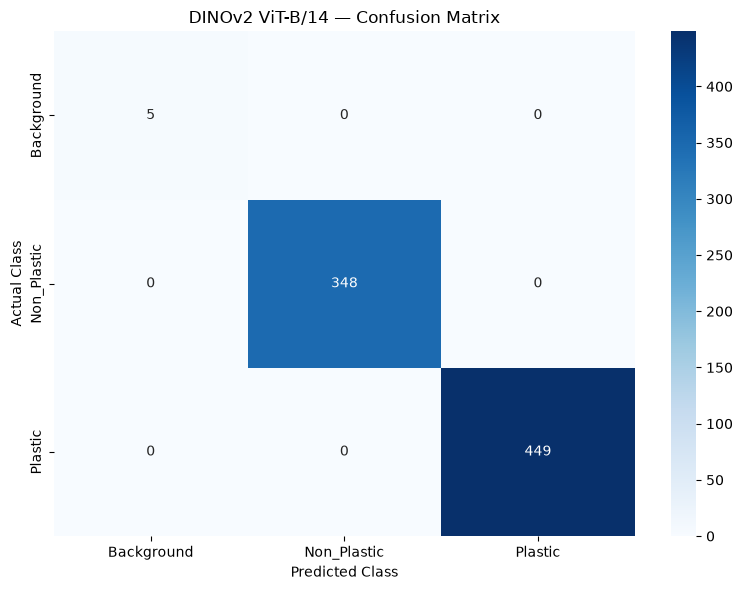


PLASTIC DETECTION RESULTS
----------------------------------------
Actual plastic images:       449
Correctly detected plastic:  449
Missed plastic images:       0
False plastic predictions:   0
Plastic detection recall:    100.00%
Plastic precision:           100.00%


In [112]:

# DINOv2 ViT-B/14 — Classification Accuracy Evaluation

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# 1. Select evaluation dataset
# --------------------------------------------------
# Uses the validation split from your existing pipeline.
# This is NOT an independent test set if used for Optuna tuning.

eval_dataset = val_dataset

eval_loader = DataLoader(
    eval_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

backbone.eval()
classifier.eval()

y_true = []
y_pred = []

# --------------------------------------------------
# 2. Run predictions
# --------------------------------------------------
with torch.inference_mode():
    for images, labels in eval_loader:
        images = images.to(device)
        labels = labels.to(device)

        features = backbone(
            pixel_values=images
        ).last_hidden_state[:, 0, :]

        logits = classifier(features)
        predictions = torch.argmax(logits, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

# --------------------------------------------------
# 3. Overall accuracy
# --------------------------------------------------
accuracy = accuracy_score(y_true, y_pred)

print("=" * 50)
print("DINOv2 ViT-B/14 EVALUATION RESULTS")
print("=" * 50)
print(f"Total images evaluated: {len(y_true)}")
print(f"Correct predictions:    {sum(a == b for a, b in zip(y_true, y_pred))}")
print(f"Incorrect predictions:  {sum(a != b for a, b in zip(y_true, y_pred))}")
print(f"Overall accuracy:       {accuracy * 100:.2f}%")

# --------------------------------------------------
# 4. Per-class precision, recall and F1
# --------------------------------------------------
print("\nCLASSIFICATION REPORT:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# --------------------------------------------------
# 5. Confusion matrix
# --------------------------------------------------
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("DINOv2 ViT-B/14 — Confusion Matrix")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Plastic detection specifically
# --------------------------------------------------
plastic_idx = class_names.index("Plastic")

actual_plastic = np.array(y_true) == plastic_idx
predicted_plastic = np.array(y_pred) == plastic_idx

true_plastic = np.sum(actual_plastic & predicted_plastic)
missed_plastic = np.sum(actual_plastic & ~predicted_plastic)
false_plastic = np.sum(~actual_plastic & predicted_plastic)

plastic_recall = (
    true_plastic / actual_plastic.sum() * 100
    if actual_plastic.sum() > 0 else 0
)

plastic_precision = (
    true_plastic / predicted_plastic.sum() * 100
    if predicted_plastic.sum() > 0 else 0
)

print("\nPLASTIC DETECTION RESULTS")
print("-" * 40)
print(f"Actual plastic images:       {actual_plastic.sum()}")
print(f"Correctly detected plastic:  {true_plastic}")
print(f"Missed plastic images:       {missed_plastic}")
print(f"False plastic predictions:   {false_plastic}")
print(f"Plastic detection recall:    {plastic_recall:.2f}%")
print(f"Plastic precision:           {plastic_precision:.2f}%")


## 5. DeiT-Small (`deit_small_patch16_224`, timm): Optuna-tuned fine-tuning

In [113]:
import sys
import torch
import torchvision

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: <venv>\Scripts\python.exe
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [115]:
from pathlib import Path

PROJECT_DIR = PROJECT_ROOT
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "deit_small_model"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA_DIR)
print("Output:", OUTPUT_DIR)
print("Classes:", [p.name for p in DATA_DIR.iterdir() if p.is_dir()])

Dataset: data
Output: deit_small_model
Classes: ['Background', 'Non_Plastic', 'Plastic']


In [116]:
import timm
import torch
import torch.nn as nn

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGE_SIZE = 224
BATCH_SIZE = 16
SEED = 42

# DeiT's standard ImageNet normalization
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        brightness=0.15, contrast=0.15, saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Separate dataset objects allow different train/evaluation transforms.
train_full = datasets.ImageFolder(DATA_DIR, transform=train_transform)
eval_full = datasets.ImageFolder(DATA_DIR, transform=eval_transform)

class_names = train_full.classes
num_classes = len(class_names)

assert train_full.class_to_idx == eval_full.class_to_idx

generator = torch.Generator().manual_seed(SEED)
train_size = int(0.8 * len(train_full))
val_size = len(train_full) - train_size

train_subset, val_subset = random_split(
    train_full, [train_size, val_size], generator=generator
)

# Apply evaluation transforms to validation images.
from torch.utils.data import Subset

val_dataset = Subset(
    eval_full,
    val_subset.indices
)

train_loader = DataLoader(
    train_subset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print("Device:", device)
print("Classes:", class_names)
print("Training images:", len(train_subset))
print("Validation images:", len(val_dataset))

Device: cuda
Classes: ['Background', 'Non_Plastic', 'Plastic']
Training images: 3205
Validation images: 802


In [117]:
model = timm.create_model(
    "deit_small_patch16_224",
    pretrained=True,
    num_classes=num_classes
)

model = model.to(device)

print("Model: DeiT-Small")
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: DeiT-Small
Parameters: 21,666,819


<venv>\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in <home>/.cache\huggingface\hub\models--timm--deit_small_patch16_224.fb_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [118]:
import optuna
import json
import copy
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

N_TRIALS = 20
MAX_EPOCHS = 50
PATIENCE = 3
SEED = 42

print("Optuna version:", optuna.__version__)
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Classes:", class_names)

Optuna version: 5.0.0
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Classes: ['Background', 'Non_Plastic', 'Plastic']


In [119]:
import timm

# Preserve the original pretrained initialization from Cell 4.
# Cell 4's model must still contain its original pretrained weights.
initial_state = {
    key: value.detach().cpu().clone()
    for key, value in model.state_dict().items()
}

def objective(trial):
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # Hyperparameters
    batch_size = trial.suggest_categorical(
        "batch_size", [8, 16, 32, 64]
    )
    learning_rate = trial.suggest_float(
        "learning_rate", 1e-5, 1e-2, log=True
    )
    weight_decay = trial.suggest_float(
        "weight_decay", 1e-6, 1e-2, log=True
    )
    dropout = trial.suggest_float(
        "dropout", 0.0, 0.4
    )
    strategy = trial.suggest_categorical(
        "strategy", ["head_only", "full_finetune"]
    )

    # Build fresh model with identical initial weights.
    trial_model = timm.create_model(
        "deit_small_patch16_224",
        pretrained=False,
        num_classes=num_classes,
        drop_rate=dropout
    )
    trial_model.load_state_dict(initial_state)
    trial_model = trial_model.to(device)

    # Train only the classifier head, or fine-tune all layers.
    if strategy == "head_only":
        for name, parameter in trial_model.named_parameters():
            parameter.requires_grad = (
                name.startswith("head.")
            )

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, trial_model.parameters()),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    criterion = nn.CrossEntropyLoss()

    trial_train_loader = DataLoader(
        train_subset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(SEED + trial.number)
    )

    trial_val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    best_loss = float("inf")
    best_accuracy = 0.0
    best_epoch = 0
    no_improvement = 0

    for epoch in range(MAX_EPOCHS):
        # Training
        trial_model.train()
        train_loss_sum = 0.0
        train_total = 0

        for images, labels in trial_train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = trial_model(images)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)
            train_total += labels.size(0)

        train_loss = train_loss_sum / max(train_total, 1)

        # Validation
        trial_model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.inference_mode():
            for images, labels in trial_val_loader:
                images = images.to(device)
                labels = labels.to(device)

                logits = trial_model(images)
                loss = criterion(logits, labels)

                val_loss_sum += loss.item() * labels.size(0)
                val_correct += (
                    logits.argmax(dim=1) == labels
                ).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_sum / max(val_total, 1)
        val_accuracy = val_correct / max(val_total, 1)

        trial.report(val_loss, step=epoch)

        if val_loss < best_loss:
            best_loss = val_loss
            best_accuracy = val_accuracy
            best_epoch = epoch + 1
            no_improvement = 0
        else:
            no_improvement += 1

        if trial.should_prune():
            del trial_model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            raise optuna.TrialPruned()

        if no_improvement >= PATIENCE:
            break

    # Store useful trial information.
    trial.set_user_attr("best_epoch", best_epoch)
    trial.set_user_attr("best_val_accuracy", best_accuracy)
    trial.set_user_attr("best_val_loss", best_loss)
    trial.set_user_attr("train_loss_last", train_loss)

    print(
        f"Trial {trial.number}: "
        f"strategy={strategy}, "
        f"batch={batch_size}, "
        f"lr={learning_rate:.2e}, "
        f"best val loss={best_loss:.5f}, "
        f"val acc={best_accuracy:.2%}"
    )

    del trial_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return best_loss


study = optuna.create_study(
    study_name="DeiT_Small_Plastic_Classification",
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=5,
        n_warmup_steps=3
    )
)

study.optimize(objective, n_trials=N_TRIALS)

print("\n========== OPTUNA COMPLETE ==========")
print("Completed trials:", len(study.trials))
print("Best validation loss:", study.best_value)
print("Best hyperparameters:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

study.trials_dataframe().to_csv(
    OUTPUT_DIR / "optuna_trials.csv", index=False
)

with open(OUTPUT_DIR / "best_hyperparameters.json", "w") as f:
    json.dump(study.best_params, f, indent=2)

Trial 0: strategy=head_only, batch=16, lr=2.94e-05, best val loss=0.00647, val acc=100.00%
Trial 1: strategy=full_finetune, batch=32, lr=4.34e-05, best val loss=0.00001, val acc=100.00%
Trial 2: strategy=head_only, batch=32, lr=7.52e-05, best val loss=0.00633, val acc=100.00%
Trial 3: strategy=head_only, batch=64, lr=3.25e-05, best val loss=0.07691, val acc=99.25%
Trial 4: strategy=head_only, batch=32, lr=2.32e-05, best val loss=0.03795, val acc=100.00%
Trial 5: strategy=head_only, batch=8, lr=3.59e-05, best val loss=0.00268, val acc=100.00%
Trial 6: strategy=full_finetune, batch=16, lr=1.37e-05, best val loss=0.00000, val acc=100.00%
Trial 7: strategy=head_only, batch=32, lr=2.55e-03, best val loss=0.00015, val acc=100.00%
Trial 9: strategy=head_only, batch=8, lr=9.45e-05, best val loss=0.00051, val acc=100.00%
Trial 10: strategy=full_finetune, batch=16, lr=2.46e-04, best val loss=0.00007, val acc=100.00%
Trial 11: strategy=full_finetune, batch=32, lr=1.08e-05, best val loss=0.00002, 

<tmp>/ipykernel_9120\2707735837.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  fig = optuna.visualization.matplotlib.plot_optimization_history(study)


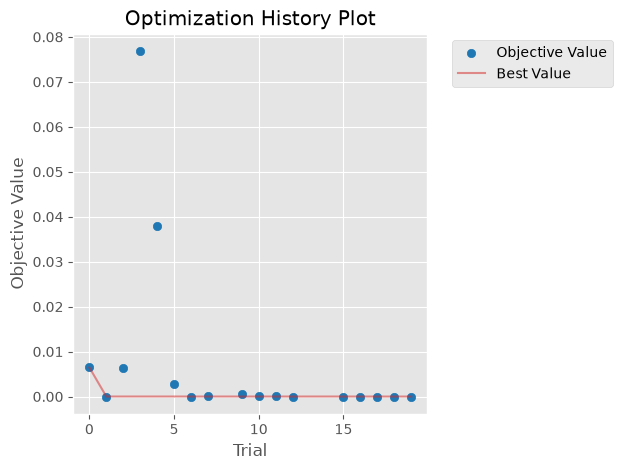

<tmp>/ipykernel_9120\2707735837.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  fig = optuna.visualization.matplotlib.plot_param_importances(study)


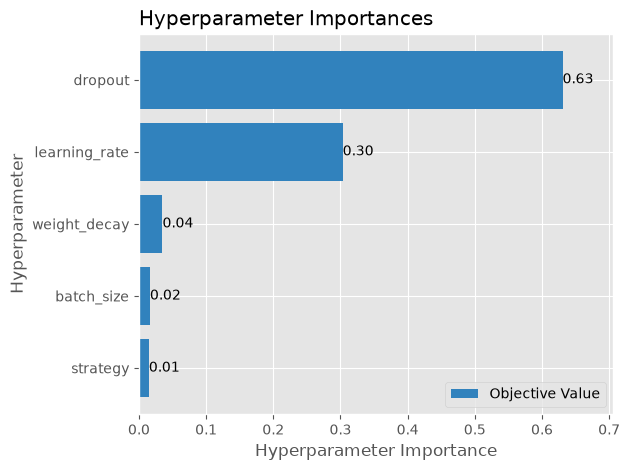

Best trial number: 19
Best loss: 3.0471196700240935e-07


In [120]:
fig = optuna.visualization.matplotlib.plot_optimization_history(study)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "optuna_optimization_history.png", dpi=200)
plt.show()

fig = optuna.visualization.matplotlib.plot_param_importances(study)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "optuna_parameter_importance.png", dpi=200)
plt.show()

print("Best trial number:", study.best_trial.number)
print("Best loss:", study.best_trial.value)

In [121]:
best_params = study.best_params

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

final_model = timm.create_model(
    "deit_small_patch16_224",
    pretrained=False,
    num_classes=num_classes,
    drop_rate=best_params["dropout"]
)

final_model.load_state_dict(initial_state)
final_model = final_model.to(device)

if best_params["strategy"] == "head_only":
    for name, parameter in final_model.named_parameters():
        parameter.requires_grad = name.startswith("head.")

final_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, final_model.parameters()),
    lr=best_params["learning_rate"],
    weight_decay=best_params["weight_decay"]
)

final_criterion = nn.CrossEntropyLoss()
final_batch_size = best_params["batch_size"]

final_train_loader = DataLoader(
    train_subset,
    batch_size=final_batch_size,
    shuffle=True,
    num_workers=0
)

final_val_loader = DataLoader(
    val_dataset,
    batch_size=final_batch_size,
    shuffle=False,
    num_workers=0
)

final_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_final_loss = float("inf")
best_final_state = None
stale_epochs = 0

for epoch in range(MAX_EPOCHS):
    final_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        final_train_loader,
        desc=f"Final training {epoch + 1}/{MAX_EPOCHS}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        final_optimizer.zero_grad(set_to_none=True)
        logits = final_model(images)
        loss = final_criterion(logits, labels)
        loss.backward()
        final_optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (logits.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    final_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in final_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = final_model(images)
            loss = final_criterion(logits, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (logits.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    final_history["train_loss"].append(train_loss)
    final_history["val_loss"].append(val_loss)
    final_history["train_acc"].append(train_acc)
    final_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}: "
        f"Train loss={train_loss:.5f}, "
        f"Val loss={val_loss:.5f}, "
        f"Train acc={train_acc:.2%}, "
        f"Val acc={val_acc:.2%}"
    )

    if val_loss < best_final_loss:
        best_final_loss = val_loss
        best_final_state = copy.deepcopy(final_model.state_dict())
        stale_epochs = 0

        torch.save({
            "model_state_dict": best_final_state,
            "class_names": class_names,
            "class_to_idx": train_full.class_to_idx,
            "image_size": IMAGE_SIZE,
            "mean": mean,
            "std": std,
            "best_val_loss": best_final_loss,
            "best_params": best_params
        }, OUTPUT_DIR / "best_model.pth")
    else:
        stale_epochs += 1

    if stale_epochs >= PATIENCE:
        print("Final training early stopped.")
        break

final_model.load_state_dict(best_final_state)

with open(OUTPUT_DIR / "final_history.json", "w") as f:
    json.dump(final_history, f, indent=2)

print("\nBest model saved:", OUTPUT_DIR / "best_model.pth")
print("Best validation loss:", best_final_loss)

Final training 1/50:   0%|          | 0/201 [00:00<?, ?it/s]

Epoch 1: Train loss=0.04282, Val loss=0.00032, Train acc=98.32%, Val acc=100.00%


Final training 2/50:   0%|          | 0/201 [00:00<?, ?it/s]

Epoch 2: Train loss=0.00030, Val loss=0.00014, Train acc=100.00%, Val acc=100.00%


Final training 3/50:   0%|          | 0/201 [00:00<?, ?it/s]

...

Epoch 48: Train loss=0.00000, Val loss=0.00000, Train acc=100.00%, Val acc=100.00%


Final training 49/50:   0%|          | 0/201 [00:00<?, ?it/s]

Epoch 49: Train loss=0.00000, Val loss=0.00000, Train acc=100.00%, Val acc=100.00%


Final training 50/50:   0%|          | 0/201 [00:00<?, ?it/s]

Epoch 50: Train loss=0.00000, Val loss=0.00000, Train acc=100.00%, Val acc=100.00%

Best model saved: deit_small_model\best_model.pth
Best validation loss: 3.182382069520682e-07


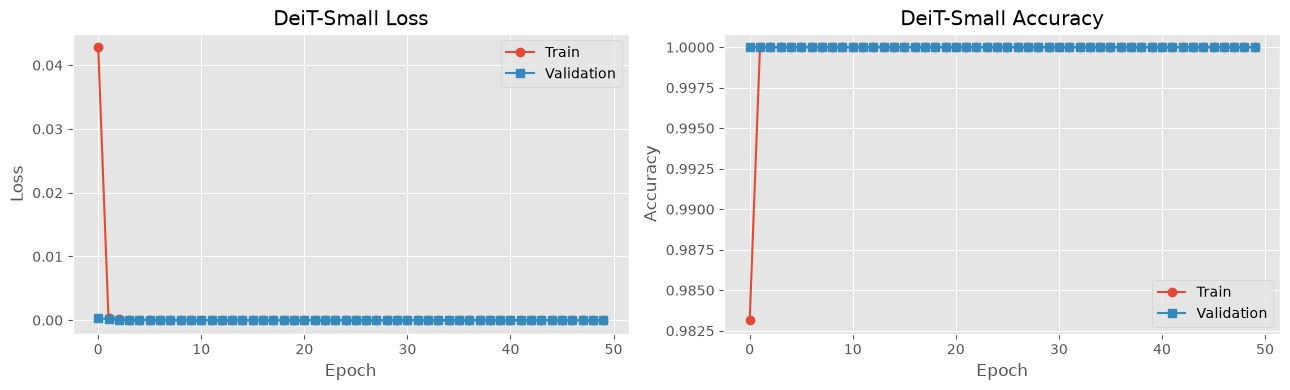

In [122]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(final_history["train_loss"], marker="o", label="Train")
axes[0].plot(final_history["val_loss"], marker="s", label="Validation")
axes[0].set_title("DeiT-Small Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(final_history["train_acc"], marker="o", label="Train")
axes[1].plot(final_history["val_acc"], marker="s", label="Validation")
axes[1].set_title("DeiT-Small Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "final_training_curves.png", dpi=200)
plt.show()

Overall validation accuracy: 100.00%
              precision    recall  f1-score   support

  Background     1.0000    1.0000    1.0000         6
 Non_Plastic     1.0000    1.0000    1.0000       330
     Plastic     1.0000    1.0000    1.0000       466

    accuracy                         1.0000       802
   macro avg     1.0000    1.0000    1.0000       802
weighted avg     1.0000    1.0000    1.0000       802



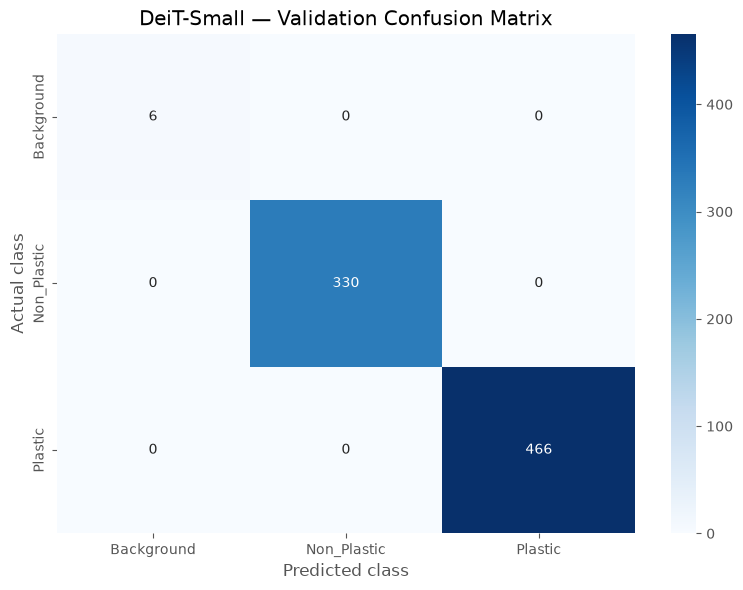

In [123]:
final_model.eval()
y_true, y_pred = [], []

with torch.inference_mode():
    for images, labels in final_val_loader:
        logits = final_model(images.to(device))
        y_pred.extend(logits.argmax(dim=1).cpu().numpy())
        y_true.extend(labels.numpy())

print(f"Overall validation accuracy: {accuracy_score(y_true, y_pred):.2%}")
print(classification_report(
    y_true, y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred, labels=list(range(num_classes))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("DeiT-Small — Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "final_confusion_matrix.png", dpi=200)
plt.show()

In [124]:

import cv2
import torch
import timm
import numpy as np
from PIL import Image
from pathlib import Path
from datetime import datetime
from timm.data import resolve_model_data_config, create_transform

# ---------- Configuration ----------
MODEL_PATH = PROJECT_ROOT / "deit_small_model" / "best_model.pth"
SAVE_DIR = PROJECT_ROOT / "webcam_test"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ImageFolder normally sorts class names alphabetically.
# Confirm these match the exact class order used during training.
CLASS_NAMES = ["Background", "Non_Plastic", "Plastic"]

MODEL_NAME = "deit_small_patch16_224"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ---------- Load trained model ----------
model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=len(CLASS_NAMES)
)

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

# Support common checkpoint formats.
if isinstance(checkpoint, dict):
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif "model" in checkpoint and isinstance(checkpoint["model"], dict):
        state_dict = checkpoint["model"]
    else:
        state_dict = checkpoint
else:
    state_dict = checkpoint

# Remove a possible DataParallel prefix.
state_dict = {
    k.removeprefix("module."): v
    for k, v in state_dict.items()
}

model.load_state_dict(state_dict, strict=True)
model = model.to(DEVICE)
model.eval()

# Use the model's expected evaluation preprocessing.
data_config = resolve_model_data_config(model)
transform = create_transform(**data_config, is_training=False)

print("Model loaded successfully.")
print("Input size:", data_config["input_size"])
print("Classes:", CLASS_NAMES)

# ---------- Webcam inference ----------
camera = cv2.VideoCapture(0)

if not camera.isOpened():
    raise RuntimeError(
        "Could not open webcam. Try changing VideoCapture(0) to VideoCapture(1)."
    )

print("\nPress Q to quit | Press S to save the current frame")

try:
    while True:
        ret, frame = camera.read()

        if not ret:
            print("Could not read webcam frame.")
            break

        # OpenCV BGR -> RGB -> PIL -> model preprocessing
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image = Image.fromarray(rgb)
        tensor = transform(image).unsqueeze(0).to(DEVICE)

        with torch.inference_mode():
            logits = model(tensor)
            probabilities = torch.softmax(logits, dim=1)[0]
            confidence, predicted_idx = torch.max(probabilities, dim=0)

        predicted_idx = predicted_idx.item()
        confidence = confidence.item()
        predicted_class = CLASS_NAMES[predicted_idx]

        # Display all class probabilities.
        cv2.putText(
            frame,
            f"Prediction: {predicted_class}",
            (15, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.85,
            (0, 255, 0),
            2
        )

        cv2.putText(
            frame,
            f"Confidence: {confidence * 100:.1f}%",
            (15, 70),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 255),
            2
        )

        y = 110
        for i, class_name in enumerate(CLASS_NAMES):
            prob = probabilities[i].item() * 100
            cv2.putText(
                frame,
                f"{class_name}: {prob:.1f}%",
                (15, y),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (255, 255, 255),
                1
            )
            y += 27

        cv2.imshow("DeiT-Small | Plastic Classification", frame)

        key = cv2.waitKey(1) & 0xFF

        if key == ord("q"):
            break

        elif key == ord("s"):
            filename = SAVE_DIR / (
                f"webcam_{datetime.now():%Y%m%d_%H%M%S}.jpg"
            )
            cv2.imwrite(str(filename), frame)
            print("Saved:", filename)

finally:
    camera.release()
    cv2.destroyAllWindows()


Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Model loaded successfully.
Input size: (3, 224, 224)
Classes: ['Background', 'Non_Plastic', 'Plastic']

Press Q to quit | Press S to save the current frame


In [125]:

from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from collections import defaultdict

DATASET_PATH = PROJECT_ROOT / "data"

dataset = ImageFolder(
    root=str(DATASET_PATH),
    transform=transform
)

print("Dataset classes:", dataset.classes)
print("Total images:", len(dataset))

# Verify class mapping before interpreting results.
if dataset.classes != CLASS_NAMES:
    raise ValueError(
        f"Class order mismatch!\n"
        f"Model configured for: {CLASS_NAMES}\n"
        f"Dataset order: {dataset.classes}\n"
        "Set CLASS_NAMES to the exact order used during training."
    )

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

correct = defaultdict(int)
total = defaultdict(int)
all_correct = 0
all_total = 0

model.eval()

with torch.inference_mode():
    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_correct += (predictions == labels).sum().item()
        all_total += labels.size(0)

        for label, pred in zip(labels.cpu().tolist(),
                               predictions.cpu().tolist()):
            total[label] += 1
            correct[label] += int(label == pred)

print(f"\nDataset accuracy: {100 * all_correct / all_total:.2f}%")

for idx, class_name in enumerate(dataset.classes):
    acc = 100 * correct[idx] / total[idx] if total[idx] else 0
    print(
        f"{class_name}: {acc:.2f}% "
        f"({correct[idx]}/{total[idx]})"
    )


Dataset classes: ['Background', 'Non_Plastic', 'Plastic']
Total images: 4007

Dataset accuracy: 100.00%
Background: 100.00% (28/28)
Non_Plastic: 100.00% (1737/1737)
Plastic: 100.00% (2242/2242)


## 6. Collecting and inspecting saved results

Exploratory cells that locate checkpoints, histories and Optuna logs for each model.

In [128]:

from pathlib import Path

ROOT = PROJECT_ROOT

print("Searching for model result files...\n")

extensions = {".csv", ".json", ".pth", ".pt", ".xlsx"}

for p in ROOT.rglob("*"):
    if p.is_file() and p.suffix.lower() in extensions:
        print(p.relative_to(ROOT))


Searching for model result files...

best_vit_model\config.json
best_vit_model\preprocessor_config.json
data\clip_inference_results.csv
data\vit_training_history.csv
deit_small_model\best_hyperparameters.json
deit_small_model\best_model.pth
deit_small_model\final_history.json
deit_small_model\optuna_trials.csv
dinov2_base_model\best_model.pth
dinov2_base_model\best_trial_history.csv
dinov2_base_model\optuna_trials.csv
dinov2_model\best_model.pth
dinov2_model\optuna_trials.csv
dinov2_model\training_history.csv
model_comparison\model_comparison.csv


In [129]:

# Check whether common training-history variables exist
for name in [
    "history", "histories", "results", "best_params",
    "study", "y_true", "y_pred"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: available ({type(obj).__name__})")
    else:
        print(f"{name}: not found")


history: available (list)
histories: not found
results: available (list)
best_params: available (dict)
study: available (Study)
y_true: available (list)
y_pred: available (list)


In [131]:
# Inspect model training and evaluation results

for name in ["history", "results", "best_params", "y_true", "y_pred"]:
    obj = globals().get(name)

    print(f"\n{'='*20} {name} {'='*20}")
    print("Type:", type(obj).__name__)

    try:
        print("Length:", len(obj))
    except TypeError:
        pass

    if name in ["history", "results", "best_params"]:
        print("Content preview:", repr(obj)[:2500])

    elif name in ["y_true", "y_pred"]:
        print("First 15 values:", repr(obj[:15]))


==================== history ====================
Type: list
Length: 4
Content preview: [{'epoch': 1, 'train_loss': 1.1932012609879433e-05, 'train_accuracy': 1.0, 'val_loss': 2.7001624215940263e-06, 'val_accuracy': 1.0}, {'epoch': 2, 'train_loss': 1.481872345122473e-06, 'train_accuracy': 1.0, 'val_loss': 1.1954928225819648e-06, 'val_accuracy': 1.0}, {'epoch': 3, 'train_loss': 7.40158908321786e-07, 'train_accuracy': 1.0, 'val_loss': 6.950097056737707e-07, 'val_accuracy': 1.0}, {'epoch': 4, 'train_loss': 4.512813917798498e-07, 'train_accuracy': 1.0, 'val_loss': 4.5537542799687337e-07, 'val_accuracy': 1.0}]

==================== results ====================
Type: list
Length: 5
Content preview: [{'Model': 'DINOv2 ViT-B/14', 'Accuracy (%)': None, 'Precision (%)': None, 'Recall (%)': None, 'F1-score (%)': None, 'Validation Loss': None}, {'Model': 'DeiT-Small', 'Accuracy (%)': None, 'Precision (%)': None, 'Recall (%)': None, 'F1-score (%)': None, 'Validation Loss': None}, {'Model': 'Model 3

In [132]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Metrics from the currently available predictions
accuracy = accuracy_score(y_true, y_pred) * 100
precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
) * 100
recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
) * 100
f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
) * 100

print("Metrics for the model that generated y_pred")
print(f"Accuracy:  {accuracy:.2f}%")
print(f"Precision: {precision:.2f}%")
print(f"Recall:    {recall:.2f}%")
print(f"F1-score:  {f1:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=["Background", "Non_Plastic", "Plastic"],
    zero_division=0
))

# Inspect the available training history
print("\nTraining history:")
for epoch in history:
    print(epoch)

Metrics for the model that generated y_pred
Accuracy:  100.00%
Precision: 100.00%
Recall:    100.00%
F1-score:  100.00%

Classification report:
              precision    recall  f1-score   support

  Background       1.00      1.00      1.00         6
 Non_Plastic       1.00      1.00      1.00       330
     Plastic       1.00      1.00      1.00       466

    accuracy                           1.00       802
   macro avg       1.00      1.00      1.00       802
weighted avg       1.00      1.00      1.00       802


Training history:
{'epoch': 1, 'train_loss': 1.1932012609879433e-05, 'train_accuracy': 1.0, 'val_loss': 2.7001624215940263e-06, 'val_accuracy': 1.0}
{'epoch': 2, 'train_loss': 1.481872345122473e-06, 'train_accuracy': 1.0, 'val_loss': 1.1954928225819648e-06, 'val_accuracy': 1.0}
{'epoch': 3, 'train_loss': 7.40158908321786e-07, 'train_accuracy': 1.0, 'val_loss': 6.950097056737707e-07, 'val_accuracy': 1.0}
{'epoch': 4, 'train_loss': 4.512813917798498e-07, 'train_accuracy':

In [133]:
from pathlib import Path

ROOT = PROJECT_ROOT

for pattern in ["*.pth", "*.pt", "*.csv", "*.json"]:
    print(f"\n--- {pattern} files ---")
    for p in ROOT.rglob(pattern):
        print(p)


--- *.pth files ---
deit_small_model\best_model.pth
dinov2_base_model\best_model.pth
dinov2_model\best_model.pth

--- *.pt files ---

--- *.csv files ---
data\clip_inference_results.csv
data\vit_training_history.csv
deit_small_model\optuna_trials.csv
dinov2_base_model\best_trial_history.csv
dinov2_base_model\optuna_trials.csv
dinov2_model\optuna_trials.csv
dinov2_model\training_history.csv
model_comparison\model_comparison.csv

--- *.json files ---
best_vit_model\config.json
best_vit_model\preprocessor_config.json
deit_small_model\best_hyperparameters.json
deit_small_model\final_history.json


In [134]:
print("Model-related variables:")
for name in list(globals()):
    if any(word in name.lower() for word in [
        "model", "test_loader", "val_loader",
        "history", "checkpoint", "class_names"
    ]):
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

Model-related variables:
CLIPModel: type
model_name: str
model: VisionTransformer
AutoModelForImageClassification: type
model_id: str
vit_model: ViTForImageClassification
CLASS_NAMES: list
MODEL_ID: str
val_loader: DataLoader
history: list
history_df: DataFrame
MODEL_DIR: WindowsPath
webcam_model: ViTForImageClassification
AutoModel: type
class_names: list
CHECKPOINT_PATH: WindowsPath
HISTORY_PATH: WindowsPath
checkpoint: dict
best_model: DINOv2Classifier
best_trial_history: list
history_files: list
checkpoint_candidates: list
checkpoint_path: WindowsPath
eval_loader: DataLoader
final_model: VisionTransformer
final_val_loader: DataLoader
final_history: dict
resolve_model_data_config: function
MODEL_PATH: WindowsPath
MODEL_NAME: str


In [135]:
from pathlib import Path

ROOT = PROJECT_ROOT

print("=== MODEL CHECKPOINTS ===")
for pattern in ["*.pth", "*.pt", "*.ckpt"]:
    for p in ROOT.rglob(pattern):
        print(f"{p.name} | {p.stat().st_size / (1024**2):.2f} MB")
        print(f"  Path: {p}")

print("\n=== EXISTING PATH VARIABLES ===")
for name in [
    "MODEL_DIR", "MODEL_PATH", "CHECKPOINT_PATH",
    "checkpoint_path", "HISTORY_PATH", "MODEL_NAME", "MODEL_ID"
]:
    if name in globals():
        print(f"{name} = {globals()[name]}")

=== MODEL CHECKPOINTS ===
best_model.pth | 82.71 MB
  Path: deit_small_model\best_model.pth
best_model.pth | 0.01 MB
  Path: dinov2_base_model\best_model.pth
best_model.pth | 84.23 MB
  Path: dinov2_model\best_model.pth

=== EXISTING PATH VARIABLES ===
MODEL_DIR = dinov2_base_model
MODEL_PATH = deit_small_model\best_model.pth
CHECKPOINT_PATH = dinov2_base_model\best_model.pth
checkpoint_path = dinov2_base_model\best_model.pth
HISTORY_PATH = dinov2_base_model\best_trial_history.csv
MODEL_NAME = deit_small_patch16_224
MODEL_ID = facebook/dinov2-base


In [136]:
print("=== HISTORY FILES ===")
if "history_files" in globals():
    for item in history_files:
        print(item)
else:
    print("No history_files variable found.")

=== HISTORY FILES ===
dinov2_base_model\best_trial_history.csv


In [138]:
import torch
from pathlib import Path

ROOT = PROJECT_ROOT

checkpoints = {
    "DeiT-Small": ROOT / "deit_small_model" / "best_model.pth",
    "DINOv2 Base": ROOT / "dinov2_base_model" / "best_model.pth",
    "DINOv2": ROOT / "dinov2_model" / "best_model.pth",
}

for name, path in checkpoints.items():
    print(f"\n{'=' * 45}")
    print(f"Model: {name}")
    print(f"File size: {path.stat().st_size / 1024:.2f} KB")

    try:
        ckpt = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        if isinstance(ckpt, dict):
            print("Checkpoint keys:", list(ckpt.keys())[:20])

            # Identify likely state dictionaries
            for key, value in ckpt.items():
                if isinstance(value, dict) and value:
                    tensor_count = sum(
                        torch.is_tensor(v) for v in value.values()
                    )
                    if tensor_count:
                        print(
                            f"  {key}: {tensor_count} tensors"
                        )
        else:
            print("Checkpoint type:", type(ckpt).__name__)

    except Exception as e:
        print("Could not inspect:", repr(e))


Model: DeiT-Small
File size: 84694.60 KB
Checkpoint keys: ['model_state_dict', 'class_names', 'class_to_idx', 'image_size', 'mean', 'std', 'best_val_loss', 'best_params']
  model_state_dict: 152 tensors

Model: DINOv2 Base
File size: 11.31 KB
Checkpoint keys: ['classifier_state_dict', 'class_names', 'class_to_idx', 'model_id', 'image_size', 'mean', 'std', 'hidden_size', 'dropout', 'batch_size', 'learning_rate', 'weight_decay', 'trial_number', 'epoch', 'val_loss']
  classifier_state_dict: 2 tensors

Model: DINOv2
File size: 86248.67 KB
Checkpoint keys: ['model_state_dict', 'class_names', 'class_to_idx', 'model_id', 'image_size', 'mean', 'std', 'dropout', 'batch_size', 'learning_rate', 'weight_decay', 'epoch', 'trial_number', 'val_loss', 'val_accuracy']
  model_state_dict: 225 tensors


In [139]:
from pathlib import Path
import torch

ROOT = PROJECT_ROOT

for folder in [
    "deit_small_model",
    "dinov2_base_model",
    "dinov2_model",
]:
    model_dir = ROOT / folder
    print(f"\n{'=' * 50}\n{folder}")

    # Print CSV and JSON files in each model folder
    for p in model_dir.iterdir():
        if p.is_file() and p.suffix.lower() in [".csv", ".json"]:
            print("Result file:", p.name)

    # Inspect checkpoint metadata
    checkpoint_files = list(model_dir.glob("*.pth"))
    for p in checkpoint_files:
        ckpt = torch.load(p, map_location="cpu", weights_only=False)
        print("\nCheckpoint:", p.name)

        for key in [
            "class_names", "class_to_idx", "model_id",
            "image_size", "best_val_loss", "val_loss",
            "val_accuracy", "epoch", "best_params"
        ]:
            if key in ckpt:
                print(f"{key}: {ckpt[key]}")


deit_small_model
Result file: best_hyperparameters.json
Result file: final_history.json
Result file: optuna_trials.csv

Checkpoint: best_model.pth
class_names: ['Background', 'Non_Plastic', 'Plastic']
class_to_idx: {'Background': 0, 'Non_Plastic': 1, 'Plastic': 2}
image_size: 224
best_val_loss: 3.182382069520682e-07
best_params: {'batch_size': 16, 'learning_rate': 0.00014097507489707086, 'weight_decay': 0.00021861543446726893, 'dropout': 0.3522235412366161, 'strategy': 'full_finetune'}

dinov2_base_model
Result file: best_trial_history.csv
Result file: optuna_trials.csv

Checkpoint: best_model.pth
class_names: ['Background', 'Non_Plastic', 'Plastic']
class_to_idx: {'Background': 0, 'Non_Plastic': 1, 'Plastic': 2}
model_id: facebook/dinov2-base
image_size: 224
val_loss: 0.0
epoch: 40

dinov2_model
Result file: optuna_trials.csv
Result file: training_history.csv

Checkpoint: best_model.pth
class_names: ['Background', 'Non_Plastic', 'Plastic']
class_to_idx: {'Background': 0, 'Non_Plastic

In [140]:
from pathlib import Path
import pandas as pd
import json

ROOT = PROJECT_ROOT

for folder in [
    "deit_small_model",
    "dinov2_base_model",
    "dinov2_model",
]:
    model_dir = ROOT / folder
    print(f"\n{'=' * 55}")
    print(f"MODEL FOLDER: {folder}")

    for filename in [
        "optuna_trials.csv",
        "best_trial_history.csv",
        "final_history.json",
        "best_hyperparameters.json",
    ]:
        path = model_dir / filename
        if not path.exists():
            continue

        print(f"\n--- {filename} ---")

        try:
            if path.suffix == ".csv":
                df = pd.read_csv(path)
                print("Columns:", df.columns.tolist())
                print(df.head(3).to_string(index=False))
            else:
                with open(path, "r", encoding="utf-8") as f:
                    data = json.load(f)
                print(json.dumps(data, indent=2)[:1800])
        except Exception as e:
            print("Read error:", e)


MODEL FOLDER: deit_small_model

--- optuna_trials.csv ---
Columns: ['number', 'value', 'datetime_start', 'datetime_complete', 'duration', 'params_batch_size', 'params_dropout', 'params_learning_rate', 'params_strategy', 'params_weight_decay', 'user_attrs_best_epoch', 'user_attrs_best_val_accuracy', 'user_attrs_best_val_loss', 'user_attrs_train_loss_last', 'system_attrs_tpe:relative_params:0', 'state']
 number    value             datetime_start          datetime_complete               duration  params_batch_size  params_dropout  params_learning_rate params_strategy  params_weight_decay  user_attrs_best_epoch  user_attrs_best_val_accuracy  user_attrs_best_val_loss  user_attrs_train_loss_last system_attrs_tpe:relative_params:0    state
      0 0.006469 2026-10-20 10:43:15.507383 2026-10-20 10:59:34.156496 0 days 00:16:18.649113                 16        0.023233              0.000029       head_only             0.000004                   50.0                           1.0               

In [143]:
from pathlib import Path
import pandas as pd

ROOT = PROJECT_ROOT

model_folders = {
    "DeiT-Small": "deit_small_model",
    "DINOv2 Base": "dinov2_base_model",
    "DINOv2": "dinov2_model",
}

summaries = []

for model_name, folder in model_folders.items():
    csv_path = ROOT / folder / "optuna_trials.csv"

    if not csv_path.exists():
        print(f"Missing: {csv_path}")
        continue

    df = pd.read_csv(csv_path)

    print(f"\n{'=' * 45}")
    print(model_name)
    print("Completed trials:", (df["state"] == "COMPLETE").sum())

    completed = df[df["state"] == "COMPLETE"].copy()

    if completed.empty:
        print("No completed trials.")
        continue

    # Optuna minimizes objective value
    best = completed.loc[completed["value"].idxmin()]

    summary = {
        "Model": model_name,
        "Best Trial": int(best["number"]),
        "Objective Value": best["value"],
    }

    for col in [
        "user_attrs_best_val_accuracy",
        "user_attrs_best_val_loss",
        "user_attrs_best_epoch",
        "params_batch_size",
        "params_learning_rate",
        "params_dropout",
        "params_weight_decay",
        "params_strategy",
    ]:
        if col in completed.columns:
            summary[col] = best[col]

    summaries.append(summary)
    print(pd.Series(summary).to_string())

summary_df = pd.DataFrame(summaries)

output_path = ROOT / "model_comparison" / "best_trial_summary.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(output_path, index=False)

print(f"\nSaved summary to:\n{output_path}")
from IPython.display import display as show_table
show_table(summary_df)


DeiT-Small
Completed trials: 17
Model                              DeiT-Small
Best Trial                                 19
Objective Value                           0.0
user_attrs_best_val_accuracy              1.0
user_attrs_best_val_loss                  0.0
user_attrs_best_epoch                    50.0
params_batch_size                          16
params_learning_rate                 0.000141
params_dropout                       0.352224
params_weight_decay                  0.000219
params_strategy                 full_finetune

DINOv2 Base
Completed trials: 10
Model                           DINOv2 Base
Best Trial                               15
Objective Value                         0.0
user_attrs_best_val_accuracy            1.0
user_attrs_best_val_loss                0.0
user_attrs_best_epoch                  40.0
params_batch_size                         8
params_learning_rate               0.005787
params_dropout                          0.2
params_weight_decay            

,Model,Best Trial,Objective Value,user_attrs_best_val_accuracy,user_attrs_best_val_loss,user_attrs_best_epoch,params_batch_size,params_learning_rate,params_dropout,params_weight_decay,params_strategy
0,DeiT-Small,19,3.047120e-07,1.0,3.047120e-07,50.0,16,0.000141,0.352224,0.000219,full_finetune
1,DINOv2 Base,15,0.000000e+00,1.0,0.000000e+00,40.0,8,0.005787,0.200000,0.000009,NaN
2,DINOv2,10,0.000000e+00,NaN,0.000000e+00,NaN,8,0.001258,0.300000,0.000001,NaN


In [144]:
from pathlib import Path

ROOT = PROJECT_ROOT

print("=== VIT / CLIP MODEL FILES ===")

for p in ROOT.rglob("*"):
    if not p.is_file():
        continue

    path_lower = str(p.relative_to(ROOT)).lower()
    if any(k in path_lower for k in ["vit", "clip"]):
        if p.suffix.lower() in {
            ".pth", ".pt", ".ckpt", ".safetensors",
            ".csv", ".json"
        }:
            print(f"{p.relative_to(ROOT)}  ({p.stat().st_size / 1024:.1f} KB)")

=== VIT / CLIP MODEL FILES ===
best_vit_model\config.json  (0.7 KB)
best_vit_model\model.safetensors  (335182.7 KB)
best_vit_model\preprocessor_config.json  (0.3 KB)
data\clip_inference_results.csv  (344.3 KB)
data\vit_training_history.csv  (1.2 KB)


In [145]:
print("\n=== VIT / CLIP VARIABLES ===")

for name in list(globals()):
    if any(k in name.lower() for k in ["vit", "clip"]):
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

        if isinstance(obj, (str, Path)):
            print("  Value:", obj)
        elif isinstance(obj, dict):
            print("  Keys:", list(obj.keys())[:15])


=== VIT / CLIP VARIABLES ===
CLIPModel: type
CLIPProcessor: type
vit_model: ViTForImageClassification


In [146]:
import pandas as pd
from pathlib import Path

ROOT = PROJECT_ROOT

files = {
    "ViT training history": ROOT / "data" / "vit_training_history.csv",
    "CLIP inference results": ROOT / "data" / "clip_inference_results.csv",
}

for name, path in files.items():
    print(f"\n{'=' * 60}")
    print(name)
    print("File exists:", path.exists())

    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(5).to_string(index=False))


ViT training history
File exists: True
Shape: (20, 5)
Columns: ['epoch', 'train_loss', 'val_loss', 'train_accuracy', 'val_accuracy']
 epoch  train_loss  val_loss  train_accuracy  val_accuracy
     1    0.000049  0.000039             1.0           1.0
     2    0.000032  0.000026             1.0           1.0
     3    0.000023  0.000019             1.0           1.0
     4    0.000016  0.000014             1.0           1.0
     5    0.000012  0.000010             1.0           1.0

CLIP inference results
File exists: True
Shape: (4007, 3)
Columns: ['filename', 'prediction', 'score']
                    filename                     prediction  score
Background_1777008251726.jpg a photo of an empty background  91.06
Background_1777008251962.jpg a photo of an empty background  95.24
Background_1777008252226.jpg a photo of an empty background  92.50
Background_1777008252460.jpg a photo of an empty background  94.72
Background_1777008252726.jpg a photo of an empty background  96.23


## 7. Five-model comparison

Builds the combined summary table and plots. All fine-tuned models reach 100% on a single validation split; see the README for why this should not be read as real-world accuracy.

CLIP images processed: 4007
CLIP prediction distribution:


,prediction,Image_Count,Mean_Score,Median_Score
0,a photo of a non-plastic object,3535,86.409219,91.650
2,a photo of plastic waste,444,63.406644,62.055
1,a photo of an empty background,28,94.061786,93.880



=== COMBINED MODEL COMPARISON ===


,Model,Best Validation Accuracy (%),Best Validation Loss,Best Epoch,Metric Source,Test Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,DeiT-Small,100.0,3.047120e-07,50.0,"final_history.json, optuna_trials.csv, checkpo...",NaN,NaN,NaN,NaN
1,DINOv2 Base,100.0,0.000000e+00,40.0,"best_trial_history.csv, optuna_trials.csv, che...",NaN,NaN,NaN,NaN
2,DINOv2,100.0,0.000000e+00,35.0,"optuna_trials.csv, checkpoint metadata",NaN,NaN,NaN,NaN
3,ViT,100.0,5.653258e-07,20.0,vit_training_history.csv,NaN,NaN,NaN,NaN
4,CLIP,NaN,NaN,NaN,clip_inference_results.csv; no ground-truth la...,NaN,NaN,NaN,NaN



CSV saved: model_comparison\all_five_models_comparison.csv


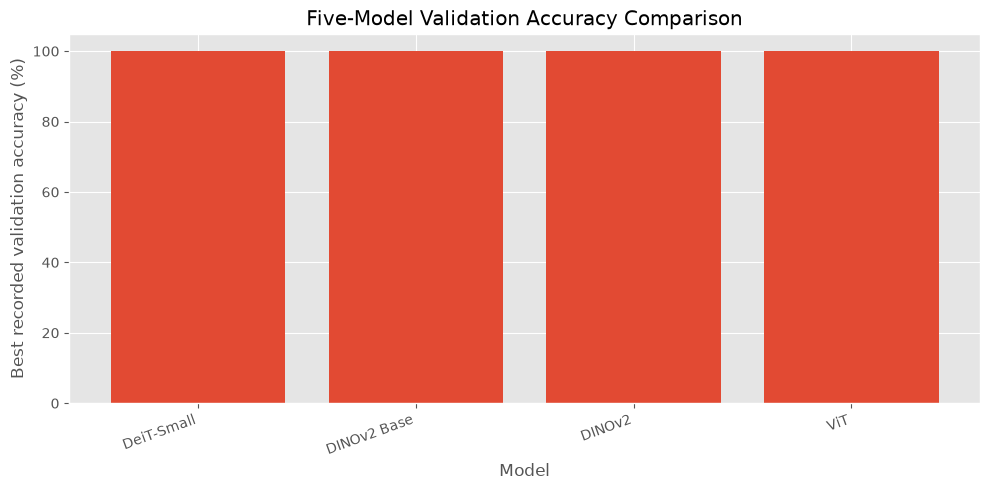

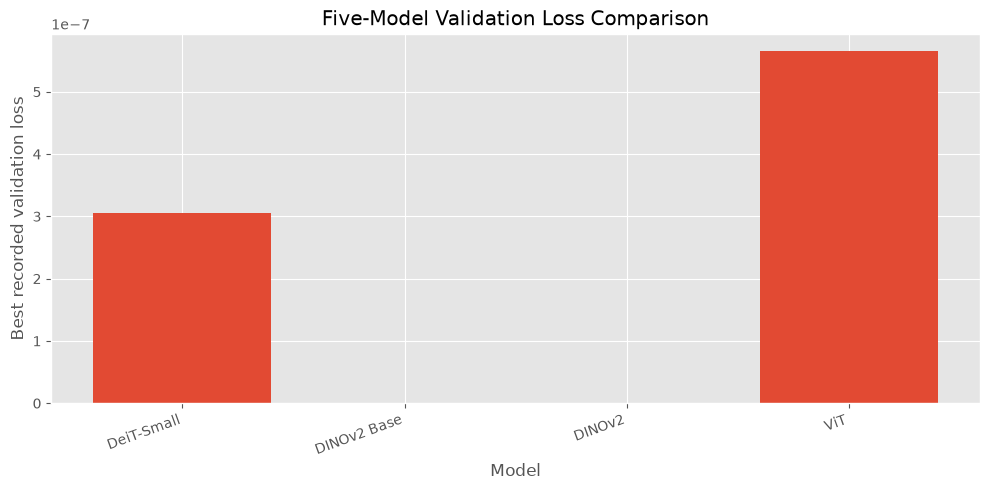


All available outputs saved in:
model_comparison


In [147]:

from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display as show_table

ROOT = PROJECT_ROOT
OUT = ROOT / "model_comparison"
OUT.mkdir(parents=True, exist_ok=True)

MODEL_FOLDERS = {
    "DeiT-Small": ROOT / "deit_small_model",
    "DINOv2 Base": ROOT / "dinov2_base_model",
    "DINOv2": ROOT / "dinov2_model",
}

rows = []

def add_model(name, accuracy=None, loss=None, epoch=None, source=""):
    rows.append({
        "Model": name,
        "Best Validation Accuracy (%)":
            round(float(accuracy) * 100, 4)
            if accuracy is not None and pd.notna(accuracy) else np.nan,
        "Best Validation Loss":
            float(loss) if loss is not None and pd.notna(loss) else np.nan,
        "Best Epoch": epoch if epoch is not None else np.nan,
        "Metric Source": source,
        "Test Accuracy (%)": np.nan,
        "Precision (%)": np.nan,
        "Recall (%)": np.nan,
        "F1-score (%)": np.nan,
    })

def get_best_history(history):
    """Accepts list-of-dicts or dict-of-lists history."""
    if isinstance(history, dict):
        keys = ["train_loss", "val_loss", "train_accuracy", "val_accuracy"]
        n = max((len(history[k]) for k in keys
                 if isinstance(history.get(k), list)), default=0)
        history = [
            {"epoch": i + 1, **{
                k: history[k][i]
                for k in keys
                if isinstance(history.get(k), list) and i < len(history[k])
            }}
            for i in range(n)
        ]

    if not isinstance(history, list) or not history:
        return None

    df = pd.DataFrame(history)
    if "val_loss" in df and df["val_loss"].notna().any():
        idx = df["val_loss"].astype(float).idxmin()
    elif "val_accuracy" in df and df["val_accuracy"].notna().any():
        idx = df["val_accuracy"].astype(float).idxmax()
    else:
        return None
    return df.loc[idx].to_dict()

# 1. DeiT-Small and both DINOv2 experiments
for name, folder in MODEL_FOLDERS.items():
    history = None
    source = []

    # Read saved epoch history, if available
    for filename in ["final_history.json", "best_trial_history.csv"]:
        path = folder / filename
        if path.exists():
            try:
                if path.suffix == ".json":
                    with open(path, encoding="utf-8") as f:
                        history = json.load(f)
                else:
                    history = pd.read_csv(path).to_dict("records")
                source.append(filename)
                break
            except Exception as e:
                print(f"Could not read {path.name}: {e}")

    best = get_best_history(history) if history is not None else None
    acc = best.get("val_accuracy") if best else None
    loss = best.get("val_loss") if best else None
    epoch = best.get("epoch") if best else None

    # Optuna trial CSV may contain the best recorded validation metrics
    trial_path = folder / "optuna_trials.csv"
    if trial_path.exists():
        trials = pd.read_csv(trial_path)
        if "state" in trials:
            trials = trials[trials["state"].astype(str).str.upper() == "COMPLETE"]
        if not trials.empty and "value" in trials:
            best_trial = trials.loc[pd.to_numeric(
                trials["value"], errors="coerce"
            ).idxmin()]

            if "user_attrs_best_val_accuracy" in trials:
                trial_acc = best_trial.get("user_attrs_best_val_accuracy")
                if pd.notna(trial_acc):
                    acc = trial_acc
            if "user_attrs_best_val_loss" in trials:
                trial_loss = best_trial.get("user_attrs_best_val_loss")
                if pd.notna(trial_loss):
                    loss = trial_loss
            if "user_attrs_best_epoch" in trials:
                trial_epoch = best_trial.get("user_attrs_best_epoch")
                if pd.notna(trial_epoch):
                    epoch = trial_epoch
            source.append("optuna_trials.csv")

    # Check checkpoint metadata for metrics where history is absent
    checkpoint_path = folder / "best_model.pth"
    if checkpoint_path.exists():
        try:
            ckpt = torch.load(
                checkpoint_path, map_location="cpu", weights_only=False
            )
            if acc is None:
                acc = ckpt.get("val_accuracy")
            if loss is None:
                loss = ckpt.get("best_val_loss", ckpt.get("val_loss"))
            if epoch is None:
                epoch = ckpt.get("epoch")
            source.append("checkpoint metadata")
        except Exception as e:
            print(f"Could not read metadata for {name}: {e}")

    add_model(name, acc, loss, epoch, ", ".join(dict.fromkeys(source)))

# 2. ViT history
vit_history_path = ROOT / "data" / "vit_training_history.csv"
if vit_history_path.exists():
    vh = pd.read_csv(vit_history_path)
    if "val_loss" in vh and vh["val_loss"].notna().any():
        best_vit = vh.loc[vh["val_loss"].idxmin()]
    elif "val_accuracy" in vh and vh["val_accuracy"].notna().any():
        best_vit = vh.loc[vh["val_accuracy"].idxmax()]
    else:
        best_vit = None

    if best_vit is not None:
        add_model(
            "ViT",
            best_vit.get("val_accuracy"),
            best_vit.get("val_loss"),
            best_vit.get("epoch"),
            "vit_training_history.csv"
        )
    else:
        add_model("ViT", source="vit_training_history.csv")

# 3. CLIP inference CSV: predictions alone do not prove accuracy
clip_path = ROOT / "data" / "clip_inference_results.csv"
if clip_path.exists():
    clip = pd.read_csv(clip_path)
    add_model(
        "CLIP",
        source="clip_inference_results.csv; no ground-truth labels"
    )

    # Summarize prediction distribution and score statistics
    clip_summary = (
        clip.groupby("prediction", dropna=False)
        .agg(
            Image_Count=("filename", "count"),
            Mean_Score=("score", "mean"),
            Median_Score=("score", "median")
        )
        .reset_index()
        .sort_values("Image_Count", ascending=False)
    )
    clip_summary.to_csv(OUT / "clip_prediction_summary.csv", index=False)

    print(f"CLIP images processed: {len(clip)}")
    print("CLIP prediction distribution:")
    show_table(clip_summary)
else:
    print("CLIP inference CSV not found.")

# 4. Save combined comparison
comparison = pd.DataFrame(rows)
comparison.to_csv(OUT / "all_five_models_comparison.csv", index=False)

print("\n=== COMBINED MODEL COMPARISON ===")
show_table(comparison)
print(f"\nCSV saved: {OUT / 'all_five_models_comparison.csv'}")

# 5. Graph: best recorded validation accuracy
plot_df = comparison.dropna(subset=["Best Validation Accuracy (%)"])
if not plot_df.empty:
    plt.figure(figsize=(10, 5))
    plt.bar(plot_df["Model"], plot_df["Best Validation Accuracy (%)"])
    plt.ylabel("Best recorded validation accuracy (%)")
    plt.xlabel("Model")
    plt.title("Five-Model Validation Accuracy Comparison")
    plt.ylim(0, 105)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(OUT / "validation_accuracy_comparison.png", dpi=200)
    plt.show()
    plt.close()
else:
    print("No comparable validation accuracy values were found.")

# 6. Graph: best recorded validation loss
plot_df = comparison.dropna(subset=["Best Validation Loss"])
if not plot_df.empty:
    plt.figure(figsize=(10, 5))
    plt.bar(plot_df["Model"], plot_df["Best Validation Loss"])
    plt.ylabel("Best recorded validation loss")
    plt.xlabel("Model")
    plt.title("Five-Model Validation Loss Comparison")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(OUT / "validation_loss_comparison.png", dpi=200)
    plt.show()
    plt.close()
else:
    print("No comparable validation loss values were found.")

print("\nAll available outputs saved in:")
print(OUT)


In [148]:

from pathlib import Path
import pandas as pd

ROOT = PROJECT_ROOT
clip_path = ROOT / "data" / "clip_inference_results.csv"

clip = pd.read_csv(clip_path)

# Extract likely ground-truth class from filename prefix
clip["true_label"] = clip["filename"].str.extract(
    r"^(Background|Non_Plastic|Plastic)_",
    expand=False
)

print("=== CLIP LABEL CHECK ===")
print("Total images:", len(clip))
print("Images with recognizable filename labels:",
      clip["true_label"].notna().sum())

print("\nGround-truth label counts:")
print(clip["true_label"].value_counts(dropna=False))

print("\nUnique CLIP predictions:")
print(clip["prediction"].value_counts(dropna=False).to_string())

print("\n=== AVAILABLE MODEL OBJECTS ===")
for name in [
    "model", "best_model", "vit_model", "webcam_model",
    "eval_loader", "val_loader", "CLASS_NAMES", "class_names"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")
        if name in ["CLASS_NAMES", "class_names"]:
            print(" ", obj)

print("\n=== EVALUATION DATASET ===")
if "eval_loader" in globals():
    print("Dataset size:", len(eval_loader.dataset))
    print("Dataset type:", type(eval_loader.dataset).__name__)
    if hasattr(eval_loader.dataset, "classes"):
        print("Dataset classes:", eval_loader.dataset.classes)


=== CLIP LABEL CHECK ===
Total images: 4007
Images with recognizable filename labels: 2270

Ground-truth label counts:
true_label
Plastic       2242
NaN           1737
Background      28
Name: count, dtype: int64

Unique CLIP predictions:
prediction
a photo of a non-plastic object    3535
a photo of plastic waste            444
a photo of an empty background       28

=== AVAILABLE MODEL OBJECTS ===
model: VisionTransformer
best_model: DINOv2Classifier
vit_model: ViTForImageClassification
webcam_model: ViTForImageClassification
eval_loader: DataLoader
val_loader: DataLoader
CLASS_NAMES: list
  ['Background', 'Non_Plastic', 'Plastic']
class_names: list
  ['Background', 'Non_Plastic', 'Plastic']

=== EVALUATION DATASET ===
Dataset size: 802
Dataset type: Subset


Models found: ['DeiT-Small', 'DINOv2 Base', 'DINOv2', 'ViT', 'CLIP']

Available columns: ['Model', 'Best Validation Accuracy (%)', 'Best Validation Loss', 'Best Epoch', 'Metric Source', 'Test Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-score (%)']
Skipping Accuracy: no actual values available.
Skipping Precision: no actual values available.
Skipping Recall: no actual values available.
Skipping F1-score: no actual values available.


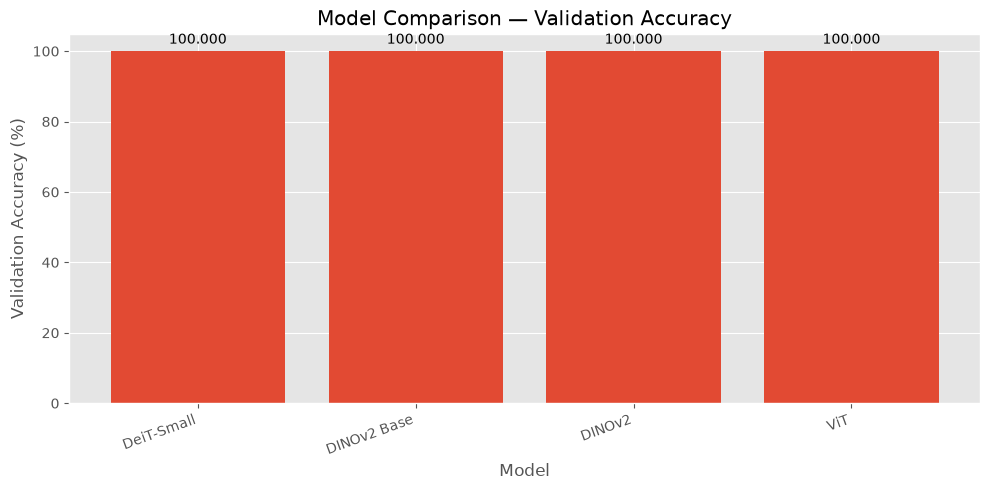

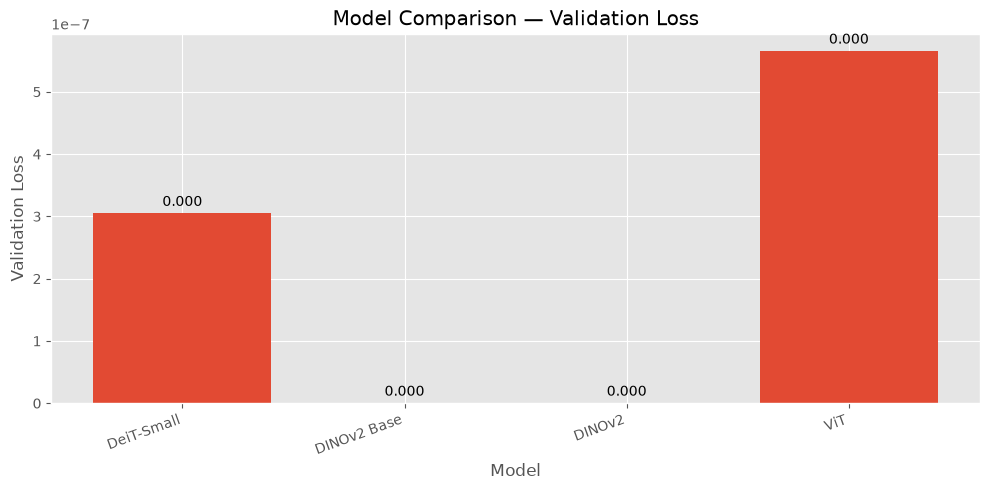

No test classification metrics available yet. Calculate test accuracy, precision, recall and F1 first.
Radar chart skipped: no complete metric rows.

Graph generation complete.
Saved to: model_comparison


In [149]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Paths
ROOT = PROJECT_ROOT
RESULTS_DIR = ROOT / "model_comparison"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = RESULTS_DIR / "all_five_models_comparison.csv"

# Load existing combined results
if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {CSV_PATH}\n"
        "Run the combined model comparison cell first."
    )

df = pd.read_csv(CSV_PATH)

print("Models found:", df["Model"].tolist())
print("\nAvailable columns:", df.columns.tolist())

# Map the actual column names to graph labels
metric_columns = {
    "Accuracy": "Test Accuracy (%)",
    "Precision": "Precision (%)",
    "Recall": "Recall (%)",
    "F1-score": "F1-score (%)",
    "Validation Accuracy": "Best Validation Accuracy (%)",
    "Validation Loss": "Best Validation Loss",
}

# Convert metric columns to numeric where present
for col in metric_columns.values():
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# --------------------------------------------------
# 1. Individual metric comparison graphs
# --------------------------------------------------
for title, column in metric_columns.items():
    if column not in df.columns:
        print(f"Skipping {title}: column not found.")
        continue

    plot_df = df[["Model", column]].dropna()

    if plot_df.empty:
        print(f"Skipping {title}: no actual values available.")
        continue

    plt.figure(figsize=(10, 5))
    bars = plt.bar(plot_df["Model"], plot_df[column])

    plt.title(f"Model Comparison — {title}")
    plt.xlabel("Model")
    plt.ylabel(title + (" (%)" if "%" in column else ""))
    plt.xticks(rotation=20, ha="right")

    if "%" in column:
        plt.ylim(0, 105)

    plt.bar_label(bars, fmt="%.3f", padding=3)
    plt.tight_layout()

    filename = title.lower().replace(" ", "_").replace("-", "_")
    plt.savefig(
        RESULTS_DIR / f"{filename}_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# --------------------------------------------------
# 2. Combined validation accuracy and test metrics
# --------------------------------------------------
combined_columns = [
    ("Test Accuracy (%)", "Test Accuracy"),
    ("Precision (%)", "Precision"),
    ("Recall (%)", "Recall"),
    ("F1-score (%)", "F1-score"),
]

available = [
    (col, label) for col, label in combined_columns
    if col in df.columns and df[col].notna().any()
]

if available:
    x = np.arange(len(df))
    width = 0.8 / len(available)

    plt.figure(figsize=(12, 6))

    for i, (col, label) in enumerate(available):
        values = df[col]
        offset = (i - (len(available) - 1) / 2) * width
        plt.bar(x + offset, values, width, label=label)

    plt.xticks(x, df["Model"], rotation=20, ha="right")
    plt.ylabel("Score (%)")
    plt.title("Five-Model Classification Metrics")
    plt.ylim(0, 105)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / "combined_classification_metrics.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()
else:
    print(
        "No test classification metrics available yet. "
        "Calculate test accuracy, precision, recall and F1 first."
    )

# --------------------------------------------------
# 3. Radar chart — only if all four metrics exist
# --------------------------------------------------
radar_columns = [
    "Test Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-score (%)",
]

if all(c in df.columns for c in radar_columns):
    radar_df = df.set_index("Model")[radar_columns].dropna()

    if not radar_df.empty:
        labels = ["Accuracy", "Precision", "Recall", "F1-score"]
        angles = np.linspace(
            0, 2 * np.pi, len(labels), endpoint=False
        ).tolist()
        angles += angles[:1]

        fig, ax = plt.subplots(
            figsize=(8, 8), subplot_kw={"polar": True}
        )

        for model_name, row in radar_df.iterrows():
            values = row.tolist()
            values += values[:1]
            ax.plot(angles, values, linewidth=2, label=model_name)
            ax.fill(angles, values, alpha=0.08)

        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(labels)
        ax.set_ylim(0, 100)
        ax.set_title("Radar Comparison of Classification Metrics", pad=25)
        ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15))

        plt.tight_layout()
        plt.savefig(
            RESULTS_DIR / "model_metrics_radar.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()
    else:
        print("Radar chart skipped: no complete metric rows.")
else:
    print("Radar chart skipped: some metric columns are missing.")

print("\nGraph generation complete.")
print("Saved to:", RESULTS_DIR)
